# Cancer meta-programmes


The 41 published meta-programmes are projected onto tumour-derived epithelial cells.
The primary analysis uses an adapted matched-null scoring framework rather than
the original 3CA assignment algorithm. Programme calls keep
low-activity and ambiguous cells explicit. Donors, not cells, are the unit for
condition comparisons. Cluster summaries describe relative enrichment and are
not propagated as cell identities.


## Setup


In [1]:
#import os
#os.environ["NUMBA_THREADING_LAYER"] = "workqueue"
#os.environ["OMP_NUM_THREADS"] = "1"
#os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"#4 Nina 2 avoid kernel crashing

In [2]:
import hashlib
import re
import sys
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import seaborn as sns

from scipy.stats import kruskal, rankdata
from statsmodels.stats.multitest import multipletests
from tqdm.auto import tqdm


/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
random_seed = 0
np.random.seed(random_seed)
sc.settings.verbosity = 2
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")


In [4]:
def find_project(start=None):
    here = Path(start or Path.cwd()).resolve()
    for parent in [here, *here.parents]:
        if (parent / "Data").is_dir() and (parent / "metadata").is_dir():
            return parent
    raise FileNotFoundError("Set CAP_PROJECT to the project data directory")


def find_publication():
    here = Path.cwd().resolve()
    for parent in [here, *here.parents]:
        for candidate in (parent, parent / "publication_notebooks"):
            if (candidate / "scripts" / "publication_figure_state.py").is_file():
                if (candidate / "data" / "cancer_meta_programme_signatures.xlsx").is_file():
                    return candidate
    raise FileNotFoundError("Run from the publication_notebooks directory")


In [5]:
project = Path(os.environ.get("CAP_PROJECT") or find_project()).expanduser().resolve()
notebook_dir = find_publication()
save_dir = project / "Adata_Saves"
df_dir = project / "Dataframe_Saves"
fig_dir = project / "Figures"

for directory in [save_dir, df_dir, fig_dir]:
    directory.mkdir(parents=True, exist_ok=True)


In [6]:
adata_file = save_dir / "epithelial_tumour_scvi.h5ad"


In [7]:
meta_programme_file = notebook_dir / "data" / "cancer_meta_programme_signatures.xlsx"


In [8]:
signature_source = ("Gavish et al. 2023, Supplementary Table 2, Cancer MPs")
signature_source_url = "https://doi.org/10.1038/s41586-023-06130-4"


In [9]:
three_ca_method_url = (
    "https://github.com/tiroshlab/3ca/blob/main/ITH_hallmarks/"
    "MPs_distribution/MP_distribution.R"
)


In [10]:
three_ca_scoring_url = ("https://github.com/jlaffy/scalop/blob/master/R/sigScores.R")


In [11]:
signature_sha256 = ("a980e87edf6b216f591e29452f85d16bdc87b510c9b5989f524096e1862ac377")


In [12]:
sample_key = "sample"
donor_key = "patient"
condition_key = "condition"
cluster_key = "epi_leiden"


In [13]:
expression_layer = "lognorm"


In [14]:
min_cells_per_sample = 100
min_signature_coverage = 0.50
n_expression_bins = 25
n_controls_per_gene = 5
n_null_signatures = 10_000
activity_familywise_alpha = 0.05
min_detected_signature_fraction = 0.20
top2_margin = 0.25
top2_margin_grid = (0.00, 0.10, 0.20, 0.25, 0.30, 0.40)
min_units_per_cluster = 3
n_permutations = 9999


## Data and signatures



The existing `patient` annotation is retained. Technical libraries from the
same donor and condition are averaged before condition-level inference. A
donor represented in more than one condition is excluded from these
comparisons so that every retained donor contributes to only one group.

In [15]:
assert adata_file.exists(), adata_file
assert meta_programme_file.exists(), meta_programme_file
actual_signature_sha256 = hashlib.sha256(meta_programme_file.read_bytes()).hexdigest()
assert actual_signature_sha256 == signature_sha256


In [16]:
pd.DataFrame([{
    "file": meta_programme_file.name,
    "source": signature_source,
    "source_url": signature_source_url,
    "sha256": actual_signature_sha256,
}]).to_csv(df_dir / "meta_programme_signature_input.csv", index=False)


In [17]:
epi = sc.read_h5ad(adata_file)


In [18]:
required_obs = {
    sample_key, donor_key, condition_key, cluster_key,
    "tumour_derived", "tumour_derived_cnv_high", "cnv_high", "cnv_score",
    "g1_cell", "phase", "n_genes_by_counts",
}
missing_obs = required_obs.difference(epi.obs.columns)
assert not missing_obs, sorted(missing_obs)
assert expression_layer in epi.layers
assert "counts" in epi.layers
assert "X_umap" in epi.obsm
assert epi.obs[donor_key].notna().all()


In [19]:
epi.obs["analysis_unit"] = (
    epi.obs[donor_key].astype(str) + "__" + epi.obs[condition_key].astype(str)
)

sample_map = epi.obs[
    [sample_key, donor_key, condition_key, "analysis_unit"]
].drop_duplicates()


In [20]:
assert not sample_map.duplicated(sample_key).any()

display(
    sample_map.groupby(condition_key, observed=True)
    .agg(samples=(sample_key, "nunique"), analysis_units=("analysis_unit", "nunique"))
)


,samples,analysis_units
condition,,
TN,8,3
HER2+,6,1
ER+,18,8
N,12,12


In [21]:
meta_programme_sheet = pd.read_excel(meta_programme_file, sheet_name="Cancer MPs")
meta_programme_sheet.columns = (
    meta_programme_sheet.columns.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
)

meta_programme_states = {}
mp_id_to_name = {}


In [22]:
for mp_name in meta_programme_sheet.columns:
    match = re.match(r"^(MP\d+)", mp_name)
    assert match is not None, mp_name

    genes = meta_programme_sheet[mp_name].dropna().astype(str).str.strip()
    genes = genes[genes.ne("")].unique().tolist()
    assert genes, mp_name

    meta_programme_states[mp_name] = genes
    mp_id_to_name[match.group(1)] = mp_name


In [23]:
assert len(meta_programme_states) == 41


In [24]:
coverage_rows = []
meta_programme_used = {}


In [25]:
for mp_name, genes in meta_programme_states.items():
    present = [gene for gene in genes if gene in epi.var_names]
    fraction = len(present) / len(genes)
    coverage_rows.append({
        "mp": mp_name,
        "n_signature_genes": len(genes),
        "n_present": len(present),
        "fraction_present": fraction,
        "used": fraction >= min_signature_coverage,
    })
    if fraction >= min_signature_coverage:
        meta_programme_used[mp_name] = present


In [26]:
signature_coverage = pd.DataFrame(coverage_rows)
signature_coverage.to_csv(df_dir / "meta_programme_signature_coverage.csv", index=False)
display(signature_coverage.round(3))


,mp,n_signature_genes,n_present,fraction_present,used
0,MP1 Cell Cycle - G2/M,50,50,1.00,True
1,MP2 Cell Cycle - G1/S,50,49,0.98,True
2,MP3 Cell Cylce HMG-rich,50,47,0.94,True
3,MP4 Chromatin,50,49,0.98,True
4,MP5 Stress,50,50,1.00,True
5,MP6 Hypoxia,50,49,0.98,True
6,MP7 Stress (in vitro),50,49,0.98,True
7,MP8 Proteasomal degradation,50,50,1.00,True
8,MP9 Unfolded protein response,50,47,0.94,True
9,MP10 Protein maturation,50,50,1.00,True


## Fixed-control programme scores


In [27]:
tumour_derived_mask = epi.obs["tumour_derived"].astype(bool).to_numpy()
tumour_derived_obs = epi.obs.loc[
    tumour_derived_mask,
    [
        sample_key, donor_key, "analysis_unit", condition_key, cluster_key,
        "n_genes_by_counts", "tumour_derived_cnv_high", "g1_cell", "phase",
    ],
].copy()


In [28]:
# A donor cannot contribute an independent observation to two condition groups.
donor_conditions = tumour_derived_obs[
    [donor_key, condition_key]
].drop_duplicates()
condition_counts = donor_conditions.groupby(
    donor_key, observed=True
)[condition_key].nunique()
cross_condition_donors = condition_counts[
    condition_counts > 1
].index.astype(str)


In [29]:
cross_condition_units = tumour_derived_obs.loc[
    tumour_derived_obs[donor_key].astype(str).isin(cross_condition_donors),
    [sample_key, donor_key, "analysis_unit", condition_key],
].drop_duplicates()
cross_condition_units.to_csv(
    df_dir / "meta_programme_cross_condition_donors.csv", index=False
)

analysis_obs = tumour_derived_obs.loc[
    ~tumour_derived_obs[donor_key].astype(str).isin(cross_condition_donors)
].copy()


In [30]:
sample_sizes = analysis_obs.groupby(sample_key, observed=True).size()
eligible_samples = sample_sizes[
    sample_sizes >= min_cells_per_sample
].index
scored_cells = analysis_obs.index[
    analysis_obs[sample_key].isin(eligible_samples)
]
scored_obs = analysis_obs.loc[scored_cells].copy()

# Keep expression matrices in exactly the same cell order as scored_obs.
scored_mask = epi.obs_names.isin(scored_cells)
assert epi.obs_names[scored_mask].equals(scored_cells)


In [31]:
x_expression = epi.layers[expression_layer][scored_mask].copy()
x_counts = epi.layers["counts"][scored_mask].copy()

eligibility = (
    tumour_derived_obs.groupby(
        [sample_key, donor_key, "analysis_unit", condition_key], observed=True
    )
    .size()
    .rename("n_tumour_derived_cells")
    .reset_index()
)


In [32]:
eligibility["cross_condition_donor"] = (
    eligibility[donor_key].astype(str).isin(cross_condition_donors)
)
eligibility["included"] = (
    eligibility["n_tumour_derived_cells"].ge(min_cells_per_sample)
    & ~eligibility["cross_condition_donor"]
)
eligibility.to_csv(
    df_dir / "meta_programme_sample_eligibility.csv", index=False
)

assert scored_obs.index.is_unique


In [33]:
assert scored_obs["analysis_unit"].notna().all()
display(cross_condition_units)
display(eligibility)
display(pd.DataFrame({
    "scored_cells": [len(scored_cells)],
    "scored_samples": [scored_obs[sample_key].nunique()],
    "analysis_units": [scored_obs["analysis_unit"].nunique()],
    "excluded_cross_condition_donors": [len(cross_condition_donors)],
}))


,sample,patient,analysis_unit,condition
barcode,,,,


,sample,patient,analysis_unit,condition,n_tumour_derived_cells,cross_condition_donor,included
0,GSM4909281_TN-MH0126,TN,TN__TN,TN,1079,False,True
1,GSM4909282_TN-MH0135,TN,TN__TN,TN,12289,False,True
2,GSM4909283_TN-SH0106,TN,TN__TN,TN,58,False,False
3,GSM4909284_TN-MH0114-T2,TN-MH0114,TN-MH0114__TN,TN,158,False,True
4,GSM4909285_TN-B1-MH4031,TN-B1,TN-B1__TN,TN,4707,False,True
5,GSM4909286_TN-B1-MH0131,TN-B1,TN-B1__TN,TN,4864,False,True
6,GSM4909287_TN-B1-Tum0554,TN-B1,TN-B1__TN,TN,2866,False,True
7,GSM4909288_TN-B1-MH0177,TN-B1,TN-B1__TN,TN,883,False,True
8,GSM4909289_HER2-AH0308,HER2,HER2__HER2+,HER2+,2996,False,True
9,GSM4909290_HER2-PM0337,HER2,HER2__HER2+,HER2+,2985,False,True


,scored_cells,scored_samples,analysis_units,excluded_cross_condition_donors
0,103371,31,12,0


In [34]:
display(pd.DataFrame({
    "scored_cells": [len(scored_cells)],
    "scored_samples": [scored_obs[sample_key].nunique()],
    "analysis_units": [scored_obs["analysis_unit"].nunique()],
}))

unit_audit = scored_obs[[
    "analysis_unit", donor_key, condition_key
]].drop_duplicates()

assert not unit_audit["analysis_unit"].duplicated().any()


,scored_cells,scored_samples,analysis_units
0,103371,31,12


In [35]:
assert unit_audit.groupby(
    "analysis_unit", observed=True
)[donor_key].nunique().max() == 1
assert unit_audit.groupby(
    "analysis_unit", observed=True
)[condition_key].nunique().max() == 1
assert unit_audit.groupby(
    donor_key, observed=True
)[condition_key].nunique().max() == 1


In [36]:
unit_audit.to_csv(
    df_dir / "meta_programme_analysis_units.csv", index=False
)


In [37]:
gene_names = pd.Index(epi.var_names.astype(str))
gene_positions = pd.Series(np.arange(len(gene_names)), index=gene_names)

gene_mean = np.asarray(x_expression.mean(axis=0)).ravel()
mean_rank = pd.Series(gene_mean, index=gene_names).rank(method="first")
gene_bin = pd.qcut(
    mean_rank,
    q=min(n_expression_bins, len(gene_names)),
    labels=False,
    duplicates="drop",
).astype(int)


In [38]:
signature_genes = set().union(*(set(genes) for genes in meta_programme_used.values()))
control_pool = gene_names[~gene_names.isin(signature_genes)]
pool_by_bin = {
    int(bin_id): control_pool[gene_bin.loc[control_pool].eq(bin_id).to_numpy()]
    for bin_id in sorted(gene_bin.unique())
}
assert len(control_pool) > 0


In [39]:
def stable_seed(label):
    digest = hashlib.sha256(f"{random_seed}|{label}".encode()).hexdigest()
    return int(digest[:8], 16)


In [40]:
def matched_gene_set(template_genes, rng, excluded=()):
    """Sample an equally sized set with the same expression-bin counts."""
    template_bins = gene_bin.loc[template_genes].value_counts().sort_index()
    selected = []
    unavailable = set(excluded)

    for target_bin, n_genes in template_bins.items():
        candidates = pool_by_bin[int(target_bin)]
        candidates = candidates[~candidates.isin(unavailable | set(selected))]

        if len(candidates) < n_genes:
            remaining = control_pool[~control_pool.isin(unavailable | set(selected))]
            distance = (gene_bin.loc[remaining] - int(target_bin)).abs()
            candidates = remaining[distance.le(distance.sort_values().iloc[n_genes - 1])]

        chosen = rng.choice(candidates, size=int(n_genes), replace=False).tolist()
        selected.extend(map(str, chosen))

    assert len(selected) == len(template_genes)
    assert len(set(selected)) == len(selected)
    return selected


In [41]:
def matched_controls(genes, label):
    rng = np.random.default_rng(stable_seed(f"controls::{label}"))
    controls = []

    for _ in range(n_controls_per_gene):
        controls.extend(matched_gene_set(genes, rng, excluded=controls))

    assert len(controls) == n_controls_per_gene * len(genes)
    return controls


In [42]:
def row_mean(matrix, genes):
    positions = gene_positions.loc[genes].to_numpy()
    values = matrix[:, positions].mean(axis=1)
    return np.asarray(values).ravel()


In [43]:
mp_scores = pd.DataFrame(index=scored_cells, dtype=float)
mp_detection = pd.DataFrame(index=scored_cells, dtype=float)
control_genes = {}
control_rows = []


In [44]:
for mp_name, genes in meta_programme_used.items():
    controls = matched_controls(genes, mp_name)
    control_genes[mp_name] = controls
    mp_scores[mp_name] = row_mean(x_expression, genes) - row_mean(x_expression, controls)

    positions = gene_positions.loc[genes].to_numpy()
    detected = x_counts[:, positions] > 0
    mp_detection[mp_name] = np.asarray(detected.mean(axis=1)).ravel()

    control_rows.append({
        "mp": mp_name,
        "n_signature_genes": len(genes),
        "n_control_genes": len(controls),
        "control_genes": ";".join(controls),
    })


In [45]:
control_audit = pd.DataFrame(control_rows)
control_audit.to_csv(df_dir / "meta_programme_fixed_controls.csv", index=False)
mp_scores.to_csv(df_dir / "meta_programme_mp_scores.csv")


In [46]:
mp_detection.to_csv(df_dir / "meta_programme_mp_detection_fraction.csv")


## Matched null and programme activity

For each meta-programme, random signatures preserve its gene count and global
expression-bin profile. Empirical null p-values are calculated separately for
every cell and meta-programme, then Holm-adjusted across all tested
meta-programmes within that cell. A meta-programme is active only when the
adjusted p-value is at most 0.05 and at least 20% of its genes have a raw count.
The null uses 10,000 random signatures and is generated here; no external
`.npy` file is required.

In [47]:
def cellwise_null_pvalues(mp_name, genes, controls, chunk_size=250):
    """Empirical upper-tail p-values from a streamed matched null."""
    rng = np.random.default_rng(stable_seed(f"null::{mp_name}"))
    control_mean = row_mean(x_expression, controls).astype(np.float32)
    observed = mp_scores[mp_name].to_numpy(dtype=np.float32)
    exceedances = np.zeros(len(scored_cells), dtype=np.int32)

    for start in range(0, n_null_signatures, chunk_size):
        stop = min(start + chunk_size, n_null_signatures)
        rows = []
        columns = []
        weights = []

        for column in range(stop - start):
            random_genes = matched_gene_set(genes, rng)
            positions = gene_positions.loc[random_genes].to_numpy()
            rows.extend(positions.tolist())
            columns.extend([column] * len(positions))
            weights.extend([1.0 / len(positions)] * len(positions))

        membership = sp.csc_matrix(
            (np.asarray(weights, dtype=np.float32), (rows, columns)),
            shape=(len(gene_names), stop - start),
        )
        random_means = x_expression @ membership
        if sp.issparse(random_means):
            random_means = random_means.toarray()
        null_scores = (
            np.asarray(random_means, dtype=np.float32) - control_mean[:, None]
        )
        exceedances += np.count_nonzero(
            null_scores >= observed[:, None], axis=1
        )

    p_values = (1 + exceedances) / (n_null_signatures + 1)
    return pd.Series(p_values, index=scored_cells, name=mp_name)


In [48]:
def holm_adjust_rows(p_values):
    """Vectorised Holm adjustment across columns within each row."""
    values = p_values.to_numpy(dtype=float)
    order = np.argsort(values, axis=1)
    ordered = np.take_along_axis(values, order, axis=1)
    factors = values.shape[1] - np.arange(values.shape[1])
    adjusted_ordered = np.maximum.accumulate(ordered * factors, axis=1)
    adjusted_ordered = np.clip(adjusted_ordered, 0, 1)

    adjusted = np.empty_like(adjusted_ordered)
    np.put_along_axis(adjusted, order, adjusted_ordered, axis=1)
    return pd.DataFrame(adjusted, index=p_values.index, columns=p_values.columns)

In [49]:
mp_empirical_p = pd.DataFrame(index=scored_cells, dtype=float)

In [50]:
for mp_name, genes in tqdm(meta_programme_used.items(), desc="matched null"):
    mp_empirical_p[mp_name] = cellwise_null_pvalues(mp_name, genes, control_genes[mp_name])

python3.11(5828) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
matched null: 100%|██████████| 41/41 [1:47:30<00:00, 157.34s/it]


In [51]:
mp_holm_p = holm_adjust_rows(mp_empirical_p)
mp_activity = (mp_holm_p.le(activity_familywise_alpha)
    & mp_detection.ge(min_detected_signature_fraction))

In [52]:
null_summary = pd.DataFrame({
    "mp": mp_empirical_p.columns,
    "minimum_empirical_p": mp_empirical_p.min(axis=0).to_numpy(),
    "median_empirical_p": mp_empirical_p.median(axis=0).to_numpy(),
    "n_holm_significant": mp_holm_p.le(activity_familywise_alpha).sum(axis=0).to_numpy(),
    "n_activity_supported": mp_activity.sum(axis=0).to_numpy()})
null_summary["n_null_signatures"] = n_null_signatures
null_summary["activity_familywise_alpha"] = activity_familywise_alpha

In [53]:
null_summary.to_csv(df_dir / "meta_programme_matched_null_summary.csv", index=False)
mp_empirical_p.to_csv(df_dir / "meta_programme_mp_empirical_p_values.csv")
mp_holm_p.to_csv(df_dir / "meta_programme_mp_holm_p_values.csv")
mp_activity.to_csv(df_dir / "meta_programme_mp_activity_calls.csv")
assert mp_activity.notna().all().all()
assert mp_holm_p.ge(mp_empirical_p - 1e-12).all().all()

## Programme classes


In [54]:
meta_programme_hallmarks = {
    "Cell Cycle": ["MP1", "MP2", "MP3", "MP4"],
    "Stress or Hypoxia": ["MP5", "MP6", "MP7"],
    "Protein Regulation": ["MP8", "MP9", "MP10", "MP11"],
    "Mesenchymal": ["MP12", "MP13", "MP14", "MP15", "MP16"],
    "Interferon and MHC II": ["MP17", "MP18"],
    "Senescence": ["MP19"],
    "Oncogenic": ["MP20"],
    "Respiration": ["MP21"],
    "Secreted": ["MP22", "MP23"],
    "Cilia": ["MP24"],
    "Neural Lineage": ["MP25", "MP26", "MP27", "MP28", "MP29"],
    "Other Lineage": ["MP30", "MP31", "MP32"],
    "Haematological Lineage": ["MP33", "MP34", "MP35", "MP36", "MP37"],
    "Unassigned": ["MP38", "MP39", "MP40", "MP41"],
}


In [55]:
meta_programme_hallmarks = {
    hallmark: [mp_id_to_name[mp_id] for mp_id in mp_ids if mp_id in mp_id_to_name]
    for hallmark, mp_ids in meta_programme_hallmarks.items()
}
candidate_hallmarks = [name for name in meta_programme_hallmarks if name != "Unassigned"]

# One programme palette is reused in every categorical programme figure.


In [56]:
programme_palette = {
    "Cell Cycle": "#2C7FB8",
    "Stress or Hypoxia": "#A6BDDB",
    "Protein Regulation": "#F28E2B",
    "Mesenchymal": "#FFBE7D",
    "Interferon and MHC II": "#2CA02C",
    "Senescence": "#98DF8A",
    "Oncogenic": "#9467BD",
    "Respiration": "#C5B0D5",
    "Secreted": "#E377C2",
    "Cilia": "#17BECF",
    "Neural Lineage": "#BCBD22",
    "Other Lineage": "#8C564B",
    "Haematological Lineage": "#D62728",
}


In [57]:
uncertainty_palette = {
    "low_activity": "#BDBDBD",
    "mixed_active_but_ambiguous": "#4D4D4D",
}
call_palette = {**programme_palette, **uncertainty_palette}
assert set(candidate_hallmarks) == set(programme_palette)


In [58]:
def robust_z(frame):
    median = frame.median(axis=0)
    mad = frame.subtract(median, axis=1).abs().median(axis=0)
    scale = (1.4826 * mad).replace(0, np.nan)
    return frame.subtract(median, axis=1).divide(scale, axis=1).fillna(0.0)


In [59]:
mp_global_z = robust_z(mp_scores)
class_score_raw = pd.DataFrame(index=scored_cells, dtype=float)
class_has_active_mp = pd.DataFrame(index=scored_cells, dtype=bool)
class_active_score_raw = pd.DataFrame(index=scored_cells, dtype=float)


In [60]:
for hallmark in candidate_hallmarks:
    members = [mp for mp in meta_programme_hallmarks[hallmark] if mp in mp_global_z.columns]
    assert members, hallmark
    class_score_raw[hallmark] = mp_global_z[members].mean(axis=1)
    class_has_active_mp[hallmark] = mp_activity[members].any(axis=1)
    class_active_score_raw[hallmark] = mp_global_z[members].where(
        mp_activity[members]
    ).mean(axis=1)


In [61]:
# Equalise class-score scales after averaging different numbers of MPs.
class_scores = robust_z(class_score_raw)
class_active_scores = class_active_score_raw.copy()


In [62]:
for hallmark in candidate_hallmarks:
    centre = class_score_raw[hallmark].median()
    scale = 1.4826 * (class_score_raw[hallmark] - centre).abs().median()
    class_active_scores[hallmark] = (
        (class_active_score_raw[hallmark] - centre) / scale if scale > 0 else np.nan
    )

class_scores.to_csv(df_dir / "meta_programme_class_scores.csv")
class_active_scores.to_csv(df_dir / "meta_programme_active_class_scores.csv")


In [63]:
mp_relative = pd.DataFrame(
    index=scored_cells, columns=mp_scores.columns, dtype=float
)


In [64]:
for sample, cell_ids in scored_obs.groupby(sample_key, observed=True).groups.items():
    mp_relative.loc[cell_ids] = robust_z(mp_scores.loc[cell_ids])


In [65]:
relative_class_scores = pd.DataFrame(index=scored_cells, dtype=float)


In [66]:
for hallmark in candidate_hallmarks:
    members = [mp for mp in meta_programme_hallmarks[hallmark] if mp in mp_relative.columns]
    relative_class_scores[hallmark] = mp_relative[members].mean(axis=1)


In [67]:
relative_class_scores.to_csv(df_dir / "meta_programme_class_scores_within_sample.csv")


In [68]:
ranking_scores = class_active_scores.where(class_has_active_mp, -np.inf)
n_active_classes = class_has_active_mp.sum(axis=1).astype(int)
has_activity = n_active_classes.gt(0)

best_class = ranking_scores.idxmax(axis=1)
ordered = np.sort(ranking_scores.to_numpy(float), axis=1)
multiple_active = n_active_classes.ge(2).to_numpy()
margin_for_rule = np.full(len(scored_cells), np.inf, dtype=float)
margin_for_rule[multiple_active] = (
    ordered[multiple_active, -1] - ordered[multiple_active, -2]
)
display_margin = np.where(multiple_active, margin_for_rule, np.nan)


In [69]:
programme_call = best_class.astype(object)
programme_call = programme_call.where(has_activity, "low_activity")
programme_call = programme_call.where(
    ~(has_activity & (margin_for_rule < top2_margin)),
    "mixed_active_but_ambiguous",
)


In [70]:
cell_summary = pd.DataFrame({
    "programme_call": programme_call,
    "best_active_class": best_class,
    "n_active_mps": mp_activity.sum(axis=1).astype(int),
    "n_active_classes": n_active_classes,
    "top2_margin": display_margin,
}, index=scored_cells)
cell_summary.to_csv(df_dir / "meta_programme_cell_programme_calls.csv")

margin_rows = []


In [71]:
for margin in top2_margin_grid:
    calls = best_class.astype(object).where(has_activity, "low_activity")
    calls = calls.where(
        ~(has_activity & (margin_for_rule < margin)),
        "mixed_active_but_ambiguous",
    )
    counts = calls.value_counts().rename_axis("programme_call").reset_index(name="n_cells")
    counts["fraction_cells"] = counts["n_cells"] / len(calls)
    counts["margin"] = margin
    margin_rows.append(counts)


In [72]:
margin_sensitivity = pd.concat(margin_rows, ignore_index=True)
margin_sensitivity.to_csv(df_dir / "meta_programme_top2_margin_sensitivity.csv", index=False)
display(cell_summary["programme_call"].value_counts().to_frame("n_cells"))


,n_cells
programme_call,
low_activity,63231
Cell Cycle,13842
Stress or Hypoxia,6382
Mesenchymal,4902
Interferon and MHC II,3622
Senescence,3160
Secreted,2166
mixed_active_but_ambiguous,1436
Neural Lineage,1125


## Published 3CA-style sensitivity

The matched-null calls above are the primary analysis. This sensitivity
reimplements the documented [3CA distribution rules](https://github.com/tiroshlab/3ca/blob/main/ITH_hallmarks/MPs_distribution/MP_distribution.R) in Python: log2(CPM/10 + 1),
row-centred signature scores with expression-bin-matched controls, at least
25 retained genes, a score threshold of 1 and a 5% within-sample frequency
filter. It is a concordance check, not output generated by `scalop`.

In [73]:
three_ca_expression_bins = 30
three_ca_controls_per_gene = 100
three_ca_min_genes = 25
three_ca_min_score = 1.0
three_ca_min_frequency = 0.05


In [74]:
def log2_cpm10(counts):
    totals = np.asarray(counts.sum(axis=1)).ravel()
    assert np.all(totals > 0)
    transformed = sp.diags(1_000_000 / totals) @ counts
    transformed = transformed.tocsr().astype(np.float32)
    transformed.data = np.log2(transformed.data / 10 + 1)
    return transformed


In [75]:
def three_ca_sample_scores(counts, sample):
    expression = log2_cpm10(counts)
    gene_means = np.asarray(expression.mean(axis=0)).ravel()

    order = np.argsort(gene_means, kind="stable")
    ordered_bins = pd.cut(
        np.arange(len(gene_names)),
        bins=three_ca_expression_bins,
        labels=False,
        include_lowest=True,
    )
    gene_bins = np.empty(len(gene_names), dtype=int)
    gene_bins[order] = np.asarray(ordered_bins, dtype=int)

    scores = pd.DataFrame(index=np.arange(counts.shape[0]), dtype=float)
    for mp_name, genes in meta_programme_used.items():
        positions = gene_positions.loc[genes].to_numpy()
        if len(positions) < three_ca_min_genes:
            continue

        rng = np.random.default_rng(stable_seed(f"3ca::{sample}::{mp_name}"))
        controls = np.concatenate([
            rng.choice(
                np.flatnonzero(gene_bins == gene_bins[position]),
                size=three_ca_controls_per_gene,
                replace=False,
            )
            for position in positions
        ])

        signature = np.asarray(expression[:, positions].mean(axis=1)).ravel()
        signature -= gene_means[positions].mean()

        weights = np.bincount(controls, minlength=len(gene_names)).astype(float)
        weights /= weights.sum()
        control = np.asarray(expression @ weights).ravel()
        control -= np.dot(gene_means, weights)
        scores[mp_name] = signature - control

    return scores


In [76]:
three_ca_scores = pd.DataFrame(
    index=scored_cells, columns=list(meta_programme_used), dtype=float
)

for sample in scored_obs[sample_key].drop_duplicates():
    mask = scored_obs[sample_key].eq(sample).to_numpy()
    sample_scores = three_ca_sample_scores(x_counts[mask], sample)
    sample_scores.index = scored_obs.index[mask]
    three_ca_scores.loc[sample_scores.index, sample_scores.columns] = sample_scores

assert three_ca_scores.notna().all().all()
three_ca_scores.to_csv(df_dir / "meta_programme_3ca_style_scores.csv")

In [77]:
three_ca_mp_call = three_ca_scores.idxmax(axis=1).astype(object)
three_ca_max_score = three_ca_scores.max(axis=1)
three_ca_mp_call = three_ca_mp_call.where(three_ca_max_score.ge(three_ca_min_score), "unassigned_low_score")

In [78]:
for sample, cell_ids in scored_obs.groupby(sample_key, observed=True).groups.items():
    sample_calls = three_ca_mp_call.loc[cell_ids]
    assigned = sample_calls[~sample_calls.eq("unassigned_low_score")]
    if assigned.empty:
        continue
    rare = assigned.value_counts(normalize=True).loc[
        lambda value: value < three_ca_min_frequency
    ].index
    rare_cells = sample_calls.index[sample_calls.isin(rare)]
    three_ca_mp_call.loc[rare_cells] = "unassigned_low_frequency"

In [79]:
mp_parent = {
    mp: parent for parent, members in meta_programme_hallmarks.items() for mp in members}
three_ca_parent_call = three_ca_mp_call.map(mp_parent).fillna(three_ca_mp_call)

In [80]:
def categorical_kappa(left, right, categories):
    observed = np.mean(left == right)
    left_frequency = pd.Series(left).value_counts(normalize=True)
    right_frequency = pd.Series(right).value_counts(normalize=True)
    expected = sum(
        left_frequency.get(category, 0) * right_frequency.get(category, 0)
        for category in categories
    )
    return (observed - expected) / (1 - expected) if expected < 1 else np.nan


In [81]:
adapted_call = programme_call.astype(str)
three_ca_call = three_ca_parent_call.astype(str)
both_assigned = (
    adapted_call.isin(candidate_hallmarks)
    & three_ca_call.isin(candidate_hallmarks))

assert both_assigned.any(), "No cells were assigned by both methods"


In [82]:
concordance = pd.DataFrame([{
    "n_scored_cells": len(scored_cells),
    "n_adapted_assigned": int(adapted_call.isin(candidate_hallmarks).sum()),
    "n_three_ca_assigned": int(three_ca_call.isin(candidate_hallmarks).sum()),
    "n_assigned_by_both": int(both_assigned.sum()),
    "agreement_assigned_by_both": float(
        np.mean(adapted_call[both_assigned] == three_ca_call[both_assigned])
    ),
    "kappa_assigned_by_both": categorical_kappa(
        adapted_call[both_assigned].to_numpy(),
        three_ca_call[both_assigned].to_numpy(),
        candidate_hallmarks,
    ),
}])


In [83]:
concordance.to_csv(df_dir / "meta_programme_3ca_style_concordance.csv", index=False)
pd.crosstab(
    adapted_call[both_assigned], three_ca_call[both_assigned]
).to_csv(df_dir / "meta_programme_3ca_style_confusion.csv")
pd.DataFrame({
    "three_ca_mp_call": three_ca_mp_call,
    "three_ca_parent_call": three_ca_parent_call,
    "three_ca_max_score": three_ca_max_score,
}).to_csv(df_dir / "meta_programme_3ca_style_calls.csv")
display(concordance.round(3))


,n_scored_cells,n_adapted_assigned,n_three_ca_assigned,n_assigned_by_both,agreement_assigned_by_both,kappa_assigned_by_both
0,103371,38704,26489,20579,0.839,0.771


## Score diagnostics


In [84]:
call_summary = (
    cell_summary["programme_call"].value_counts()
    .rename_axis("programme_call")
    .reset_index(name="n_cells")
)
call_summary["fraction"] = call_summary["n_cells"] / call_summary["n_cells"].sum()
call_summary.to_csv(df_dir / "meta_programme_programme_call_summary.csv", index=False)
display(call_summary)


,programme_call,n_cells,fraction
0,low_activity,63231,0.611690
1,Cell Cycle,13842,0.133906
2,Stress or Hypoxia,6382,0.061739
3,Mesenchymal,4902,0.047421
4,Interferon and MHC II,3622,0.035039
5,Senescence,3160,0.030570
6,Secreted,2166,0.020954
7,mixed_active_but_ambiguous,1436,0.013892
8,Neural Lineage,1125,0.010883
9,Protein Regulation,1080,0.010448


In [85]:
uncertain = margin_sensitivity[
    margin_sensitivity["programme_call"].isin(
        ["low_activity", "mixed_active_but_ambiguous"]
    )
]


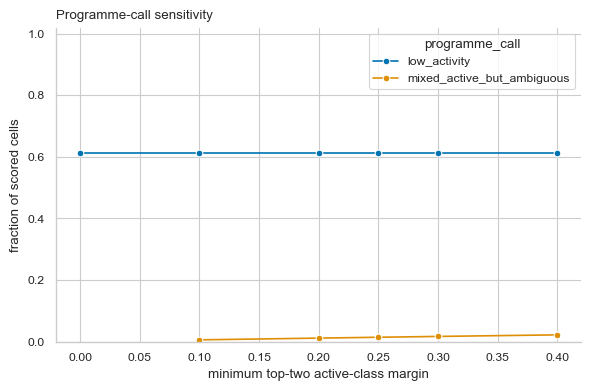

In [86]:
fig, ax = plt.subplots(figsize=(6, 4))

sns.lineplot(
    data=uncertain,
    x="margin",
    y="fraction_cells",
    hue="programme_call",
    marker="o",
    ax=ax,
)
ax.set_xlabel("minimum top-two active-class margin")
ax.set_ylabel("fraction of scored cells")
ax.set_ylim(0, 1.02)
ax.set_title("Programme-call sensitivity", loc="left")

ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(fig_dir / "meta_programme_threshold_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()


## Donor-centred cluster enrichment



These summaries show which programme score is relatively elevated in each
Leiden cluster after subtracting each donor-condition unit's overall mean.
They do not define cell identities or programme prevalence.

In [87]:
cluster_frame = class_scores.join(
    scored_obs[[cluster_key, "analysis_unit", condition_key]]
)

unit_means = cluster_frame.groupby("analysis_unit", observed=True)[candidate_hallmarks].mean()
cluster_unit_means = cluster_frame.groupby(
    [cluster_key, "analysis_unit"], observed=True
)[candidate_hallmarks].mean()

cluster_unit_deviation = cluster_unit_means.copy()


In [88]:
for cluster, unit in cluster_unit_deviation.index:
    cluster_unit_deviation.loc[(cluster, unit)] -= unit_means.loc[unit]


In [89]:
cluster_deviation = cluster_unit_deviation.groupby(level=0, observed=True).agg(
    ["mean", "median", "count"]
)


In [90]:
cluster_rows = []


In [91]:
for cluster, values in cluster_unit_deviation.groupby(level=0, observed=True):
    values = values.droplevel(0)
    mean_deviation = values.mean(axis=0)
    supported = len(values) >= min_units_per_cluster
    top_class = mean_deviation.idxmax() if supported else "insufficient_support"

    loo_top = []
    if supported:
        for unit in values.index:
            loo_top.append(values.drop(index=unit).mean(axis=0).idxmax())

    cluster_rows.append({
        cluster_key: cluster,
        "n_analysis_units": len(values),
        "leading_relative_enrichment": top_class,
        "leading_mean_deviation": (
            float(mean_deviation.loc[top_class]) if supported else np.nan
        ),
        "loo_leading_class_agreement": (
            float(np.mean(np.asarray(loo_top) == top_class)) if loo_top else np.nan
        ),
    })


In [92]:
cluster_stability = pd.DataFrame(cluster_rows)


In [93]:
cluster_stability.to_csv(df_dir / "meta_programme_cluster_donor_stability.csv", index=False)
display(cluster_stability)


,epi_leiden,n_analysis_units,leading_relative_enrichment,leading_mean_deviation,loo_leading_class_agreement
0,0,12,Senescence,1.289956,1.00
1,1,10,Neural Lineage,0.301398,1.00
2,2,11,Secreted,2.401771,1.00
3,3,12,Cell Cycle,3.302967,1.00
4,4,12,Respiration,0.869744,1.00
5,5,12,Respiration,0.210156,1.00
6,6,10,Haematological Lineage,1.697830,1.00
7,7,12,Neural Lineage,0.175427,1.00
8,8,12,Haematological Lineage,0.376959,1.00
9,9,12,Stress or Hypoxia,0.629598,1.00


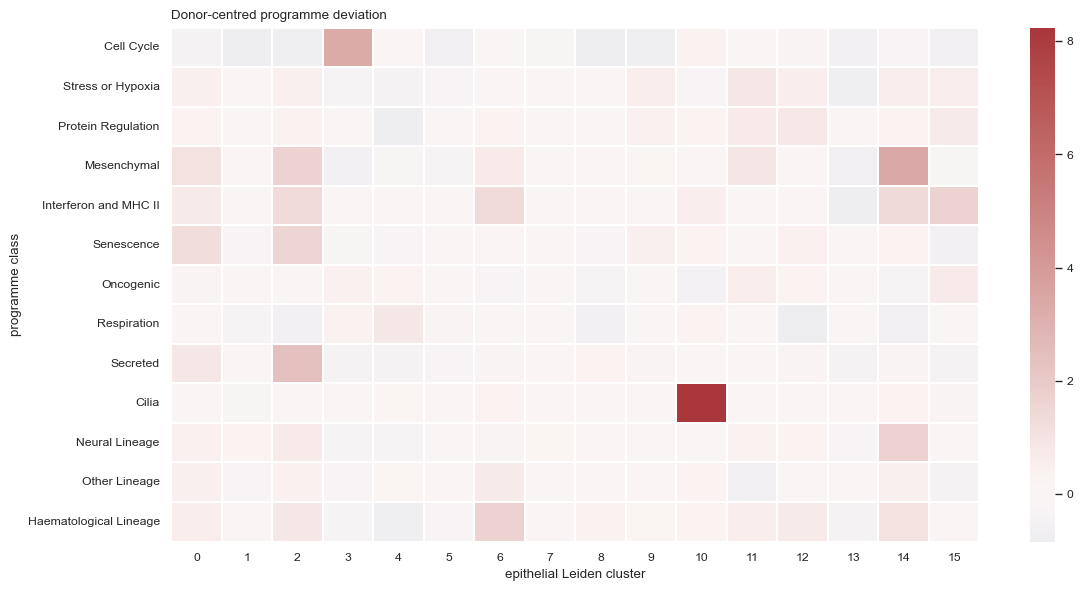

In [94]:
cluster_heatmap = cluster_unit_deviation.groupby(level=0, observed=True).mean().T
cluster_heatmap = cluster_heatmap.reindex(candidate_hallmarks)
supported_clusters = cluster_stability.loc[
    cluster_stability["n_analysis_units"].ge(min_units_per_cluster), cluster_key
]
cluster_heatmap = cluster_heatmap.loc[:, supported_clusters]

fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    cluster_heatmap,
    cmap="vlag",
    center=0,
    linewidths=0.2,
    linecolor="white",
    ax=ax,
)
ax.set_xlabel("epithelial Leiden cluster")
ax.set_ylabel("programme class")
ax.set_title("Donor-centred programme deviation", loc="left")
fig.tight_layout()

fig.savefig(fig_dir / "meta_programme_cluster_donor_deviation.png", dpi=300, bbox_inches="tight")
plt.show()

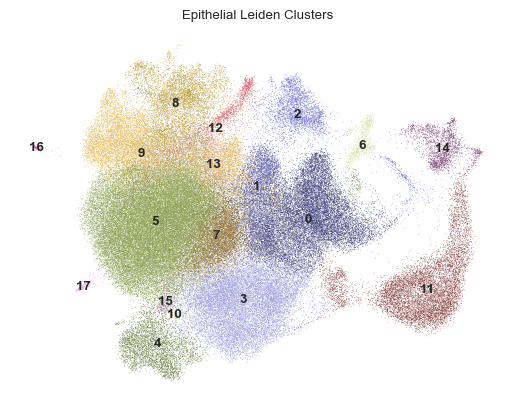

In [95]:
sc.pl.umap(epi, color='epi_leiden', legend_loc='on data', title='Epithelial Leiden Clusters', frameon=False, palette='tab20b')


## Donor-level programme calls



Fractions use formal matched-null calls. Low-activity and ambiguous cells stay
in the denominator. Technical libraries are averaged within donor by
condition before condition summaries and permutation tests.

In [96]:
assignment = scored_obs[
    [
        sample_key, "analysis_unit", condition_key, "n_genes_by_counts",
        "tumour_derived_cnv_high", "g1_cell", "phase",
    ]
].copy()
assignment[condition_key] = assignment[condition_key].astype(str)
assignment["programme_call"] = cell_summary["programme_call"].astype(str)

composition_categories = candidate_hallmarks + [
    "low_activity", "mixed_active_but_ambiguous"
]


In [97]:
def composition_by_unit(frame):
    sample_profiles = pd.crosstab(
        [frame[sample_key], frame["analysis_unit"], frame[condition_key]],
        frame["programme_call"],
        normalize="index",
    ).reset_index()

    for category in composition_categories:
        if category not in sample_profiles:
            sample_profiles[category] = 0.0

    unit_profiles = (
        sample_profiles
        .groupby(["analysis_unit", condition_key], observed=True)[composition_categories]
        .mean()
        .reset_index()
    )
    unit_profiles[condition_key] = unit_profiles[condition_key].astype(str)
    assert np.allclose(unit_profiles[composition_categories].sum(axis=1), 1.0)
    return sample_profiles, unit_profiles


In [98]:
sample_composition, unit_composition = composition_by_unit(assignment)


In [99]:
min_gene_assignment = assignment[
    assignment["n_genes_by_counts"] >= 500
].copy()
sample_composition_min_genes, unit_composition_min_genes = composition_by_unit(
    min_gene_assignment
)


In [100]:
cnv_high_assignment = assignment[
    assignment["tumour_derived_cnv_high"]
].copy()
cnv_high_sample_sizes = cnv_high_assignment.groupby(
    sample_key, observed=True
).size()


In [101]:
cnv_high_eligible_samples = cnv_high_sample_sizes[
    cnv_high_sample_sizes >= min_cells_per_sample
].index
cnv_high_assignment = cnv_high_assignment[
    cnv_high_assignment[sample_key].isin(cnv_high_eligible_samples)
]
sample_composition_cnv_high, unit_composition_cnv_high = composition_by_unit(
    cnv_high_assignment
)


In [102]:
cnv_high_g1_assignment = assignment[
    assignment["tumour_derived_cnv_high"] & assignment["g1_cell"]
].copy()
cnv_high_g1_sample_sizes = cnv_high_g1_assignment.groupby(
    sample_key, observed=True
).size()
cnv_high_g1_eligible_samples = cnv_high_g1_sample_sizes[
    cnv_high_g1_sample_sizes >= min_cells_per_sample
].index
cnv_high_g1_assignment = cnv_high_g1_assignment[
    cnv_high_g1_assignment[sample_key].isin(cnv_high_g1_eligible_samples)
]
sample_composition_cnv_high_g1, unit_composition_cnv_high_g1 = composition_by_unit(
    cnv_high_g1_assignment
)


In [103]:
complexity_sensitivity = (
    assignment.assign(low_complexity=assignment["n_genes_by_counts"] < 500)
    .groupby(condition_key, observed=True)
    .agg(
        n_tumour_derived_cells=("low_complexity", "size"),
        n_below_500_genes=("low_complexity", "sum"),
    )
    .reset_index()
)


In [104]:
cnv_high_eligibility = (
    assignment.groupby([sample_key, "analysis_unit", condition_key], observed=True)
    .agg(
        n_tumour_derived_cells=("tumour_derived_cnv_high", "size"),
        n_cnv_high=("tumour_derived_cnv_high", "sum"),
        n_cnv_high_g1=("g1_cell", lambda x: int(
            (x & assignment.loc[x.index, "tumour_derived_cnv_high"]).sum()
        )),
    )
    .reset_index()
)


In [105]:
cnv_high_eligibility["included"] = (
    cnv_high_eligibility["n_cnv_high"] >= min_cells_per_sample
)

unit_composition.to_csv(
    df_dir / "meta_programme_donor_profiles.csv", index=False
)
unit_composition_min_genes.to_csv(
    df_dir / "meta_programme_donor_profiles_min_500_genes.csv", index=False
)


In [106]:
unit_composition_cnv_high.to_csv(
    df_dir / "meta_programme_donor_profiles_cnv_high.csv", index=False
)
complexity_sensitivity.to_csv(
    df_dir / "meta_programme_min_genes_sensitivity.csv", index=False
)
cnv_high_eligibility.to_csv(
    df_dir / "meta_programme_cnv_high_eligibility.csv", index=False
)

display(complexity_sensitivity.round(4))
display(cnv_high_eligibility)


,condition,n_tumour_derived_cells,n_below_500_genes
0,ER+,59992,9024
1,HER2+,16533,1497
2,TN,26846,1448


,sample,analysis_unit,condition,n_tumour_derived_cells,n_cnv_high,n_cnv_high_g1,included
0,GSM4909281_TN-MH0126,TN__TN,TN,1079,721,341,True
1,GSM4909282_TN-MH0135,TN__TN,TN,12289,5697,1448,True
2,GSM4909284_TN-MH0114-T2,TN-MH0114__TN,TN,158,49,29,False
3,GSM4909285_TN-B1-MH4031,TN-B1__TN,TN,4707,1011,382,True
4,GSM4909286_TN-B1-MH0131,TN-B1__TN,TN,4864,455,281,True
5,GSM4909287_TN-B1-Tum0554,TN-B1__TN,TN,2866,1065,275,True
6,GSM4909288_TN-B1-MH0177,TN-B1__TN,TN,883,263,111,True
7,GSM4909289_HER2-AH0308,HER2__HER2+,HER2+,2996,356,245,True
8,GSM4909290_HER2-PM0337,HER2__HER2+,HER2+,2985,397,145,True
9,GSM4909291_HER2-MH0031,HER2__HER2+,HER2+,1449,1098,673,True


In [107]:
unit_composition_cnv_high_g1.to_csv(
    df_dir / "meta_programme_donor_profiles_cnv_high_g1.csv", index=False
)


In [108]:
condition_order = ["TN", "HER2+", "ER+"]
condition_palette = {"TN": "#976391", "HER2+": "#2CA02C", "ER+": "#F46036"}

long_composition = unit_composition.melt(
    id_vars=["analysis_unit", condition_key],
    value_vars=candidate_hallmarks,
    var_name="programme",
    value_name="fraction",
)


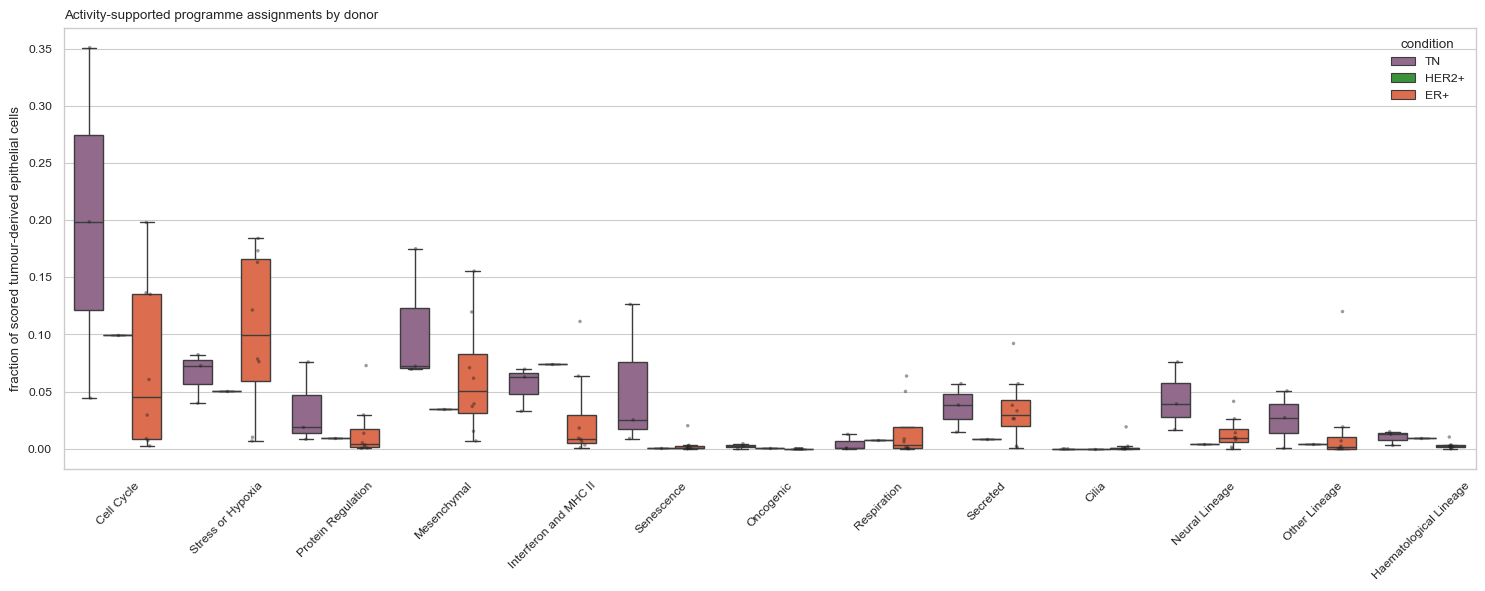

In [109]:
fig, ax = plt.subplots(figsize=(15, 6))
sns.boxplot(
    data=long_composition,
    x="programme",
    y="fraction",
    hue=condition_key,
    order=candidate_hallmarks,
    hue_order=condition_order,
    palette=condition_palette,
    showfliers=False,
    ax=ax,
)

sns.stripplot(
    data=long_composition,
    x="programme",
    y="fraction",
    hue=condition_key,
    order=candidate_hallmarks,
    hue_order=condition_order,
    dodge=True,
    palette={condition: "#222222" for condition in condition_order},
    alpha=0.45,
    size=2.5,
    legend=False,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("fraction of scored tumour-derived epithelial cells")
ax.set_title("Activity-supported programme assignments by donor", loc="left")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False, title="condition")
fig.tight_layout()
fig.savefig(fig_dir / "meta_programme_programme_donor_composition.png", dpi=300, bbox_inches="tight")
plt.show()


## Condition-level programme overview

Each donor-condition unit contributes once. The stacked bars include
low-activity and ambiguous cells, so every bar sums to one. This is an overview;
the donor-level box-and-point plot above retains the biological variability.


In [110]:
overview_order = candidate_hallmarks + [
    "low_activity", "mixed_active_but_ambiguous"
]
overview_palette = {**programme_palette, **uncertainty_palette}

condition_composition = (
    unit_composition
    .groupby(condition_key, observed=True)[overview_order]
    .mean()
    .reindex(condition_order)
)


In [111]:
n_units = unit_composition.groupby(condition_key, observed=True)[
    "analysis_unit"
].nunique()
n_cells = scored_obs.groupby(condition_key, observed=True).size()


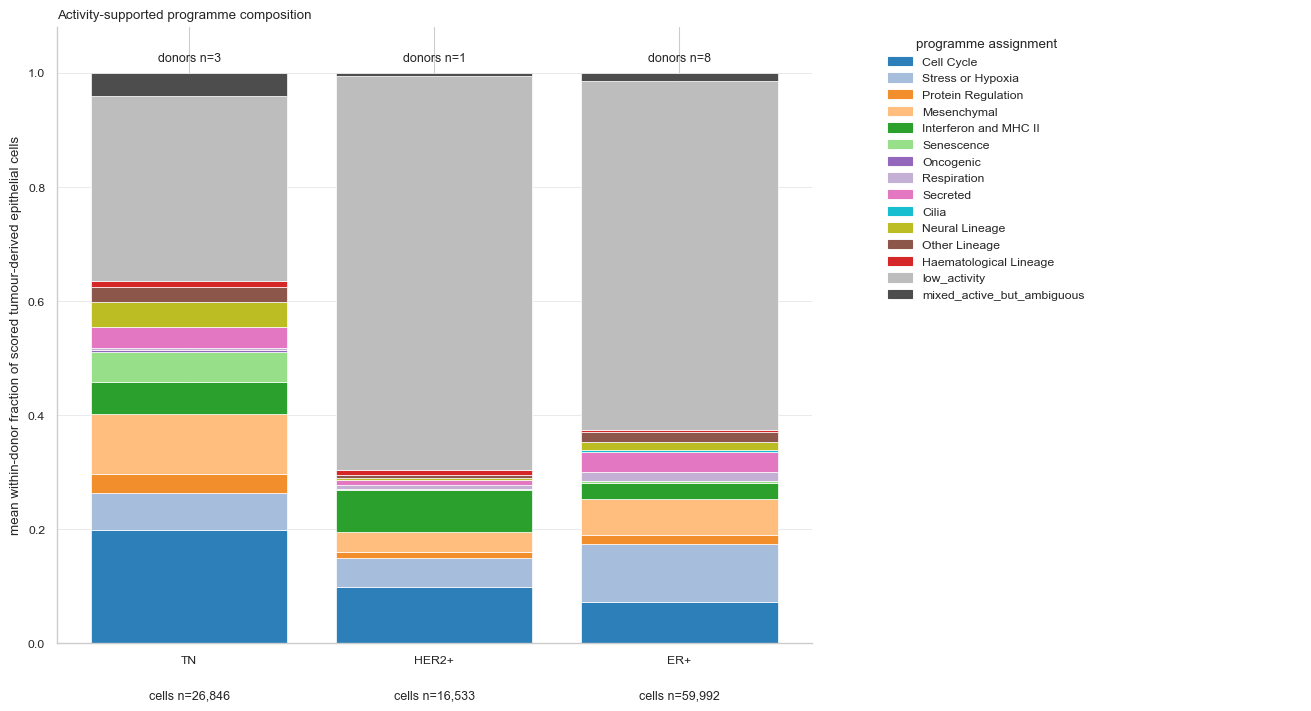

In [112]:
fig, (ax, legend_ax) = plt.subplots(
    1, 2,
    figsize=(13, 7),
    gridspec_kw={"width_ratios": [3.2, 1.8], "wspace": 0.10},
    layout="constrained",
)
positions = np.arange(len(condition_order))

bottom = np.zeros(len(condition_order))

for programme in overview_order:
    values = condition_composition[programme].to_numpy()
    ax.bar(
        positions,
        values,
        bottom=bottom,
        color=overview_palette[programme],
        edgecolor="white",
        linewidth=0.5,
        label=programme,
    )
    bottom += values

for position, condition in enumerate(condition_order):
    ax.text(
        position, 1.015,
        f"donors n={int(n_units.get(condition, 0))}",
        ha="center", va="bottom", fontsize=9,
    )
    ax.text(
        position, -0.08,
        f"cells n={int(n_cells.get(condition, 0)):,}",
        ha="center", va="top", fontsize=9,
    )


ax.set_xticks(positions, condition_order)
ax.set_ylim(0, 1.08)
ax.set_ylabel("mean within-donor fraction of scored tumour-derived epithelial cells")
ax.set_xlabel("")
ax.set_title("Activity-supported programme composition", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E5E7EB", linewidth=0.6)
ax.set_axisbelow(True)

legend_ax.axis("off")


legend_ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=overview_palette[x], label=x)
        for x in overview_order
    ],
    title="programme assignment",
    loc="upper left",
    frameon=False,
)

for suffix in ["svg", "pdf", "png"]:
    fig.savefig(
        fig_dir / f"meta_programme_programme_composition_by_condition.{suffix}",
        dpi=600 if suffix == "png" else None,
        bbox_inches="tight",
    )
 
plt.show()

condition_composition.to_csv(
    df_dir / "meta_programme_programme_composition_by_condition.csv"
)


## Cluster-enrichment decomposition



This panel shows all 41 individual meta-programmes, grouped by their parent
class, across the cluster groups defined above. Dot colour is the mean
donor-centred deviation and dot size is the fraction of donor-condition units
with a positive deviation. Because the same MP scores define the cluster groups,
this is a descriptive quality-control figure rather than independent validation.
Row labels identify the largest relative deviation only; they do not establish
selective or statistically significant programme activity.


In [113]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D


In [114]:
cluster_display = cluster_stability.copy()
cluster_display["display_group"] = cluster_display[
    "leading_relative_enrichment"
].astype(str)
stable = (
    cluster_display["n_analysis_units"].ge(min_units_per_cluster)
    & cluster_display["loo_leading_class_agreement"].ge(0.80)
)
cluster_display.loc[~stable, "display_group"] = "Unresolved"

cluster_group_map = cluster_display.set_index(cluster_key)["display_group"]
cluster_group_map.index = cluster_group_map.index.astype(str)


In [115]:
group_meta = scored_obs[[cluster_key, "analysis_unit"]].copy()
group_meta["cluster_string"] = group_meta[cluster_key].astype(str)
group_meta["display_group"] = group_meta["cluster_string"].map(cluster_group_map)
assert group_meta["display_group"].notna().all()


In [116]:
unit_overall_mp = (
    mp_global_z.join(group_meta[["analysis_unit"]])
    .groupby("analysis_unit", observed=True)
    .mean()
)
unit_group_mp = (
    mp_global_z.join(group_meta[["analysis_unit", "display_group"]])
    .groupby(["analysis_unit", "display_group"], observed=True)
    .mean()
)
unit_group_deviation = unit_group_mp.copy()


In [117]:
for unit, group in unit_group_deviation.index:
    unit_group_deviation.loc[(unit, group)] -= unit_overall_mp.loc[unit]


In [118]:
group_mp_long = (
    unit_group_deviation
    .reset_index()
    .melt(
        id_vars=["analysis_unit", "display_group"],
        value_vars=list(mp_global_z.columns),
        var_name="mp_name",
        value_name="unit_centred_mp_deviation",
    )
)


In [119]:
group_mp_summary = (
    group_mp_long
    .groupby(["display_group", "mp_name"], observed=True, as_index=False)
    .agg(
        mean_unit_centred_deviation=("unit_centred_mp_deviation", "mean"),
        fraction_units_positive=(
            "unit_centred_mp_deviation", lambda x: (x > 0).mean()
        ),
        n_units=("unit_centred_mp_deviation", "size"),
    )
)


In [120]:
group_order = [
    group for group in candidate_hallmarks
    if group in set(group_mp_summary["display_group"])
]


In [121]:
if "Unresolved" in set(group_mp_summary["display_group"]):
    group_order.append("Unresolved")


In [122]:
mp_order = [
    mp
    for parent_class, members in meta_programme_hallmarks.items()
    for mp in members
    if mp in mp_global_z.columns
]

mp_axis_labels = {}
for mp in mp_order:
    corrected = mp.replace("Cell Cylce", "Cell Cycle")
    mp_id, description = corrected.split(" ", 1)
    mp_axis_labels[mp] = f"{mp_id}  {description}"


In [123]:
mp_x = {}
parent_spans = []
x_cursor = 0.0


In [124]:
for parent_class, members in meta_programme_hallmarks.items():
    present = [mp for mp in members if mp in mp_order]
    if not present:
        continue

    start = x_cursor
    for mp in present:
        mp_x[mp] = x_cursor
        x_cursor += 1.0
    end = x_cursor - 1.0
    parent_spans.append((parent_class, start, end))
    x_cursor += 0.45


In [125]:
plot_summary = group_mp_summary.copy()
plot_summary["x"] = plot_summary["mp_name"].map(mp_x)
plot_summary["y"] = plot_summary["display_group"].map(
    {group: i for i, group in enumerate(group_order)}
)
plot_summary = plot_summary.dropna(subset=["x", "y"])

limit = float(np.quantile(
    np.abs(plot_summary["mean_unit_centred_deviation"]), 0.98
))
limit = max(limit, 0.1)


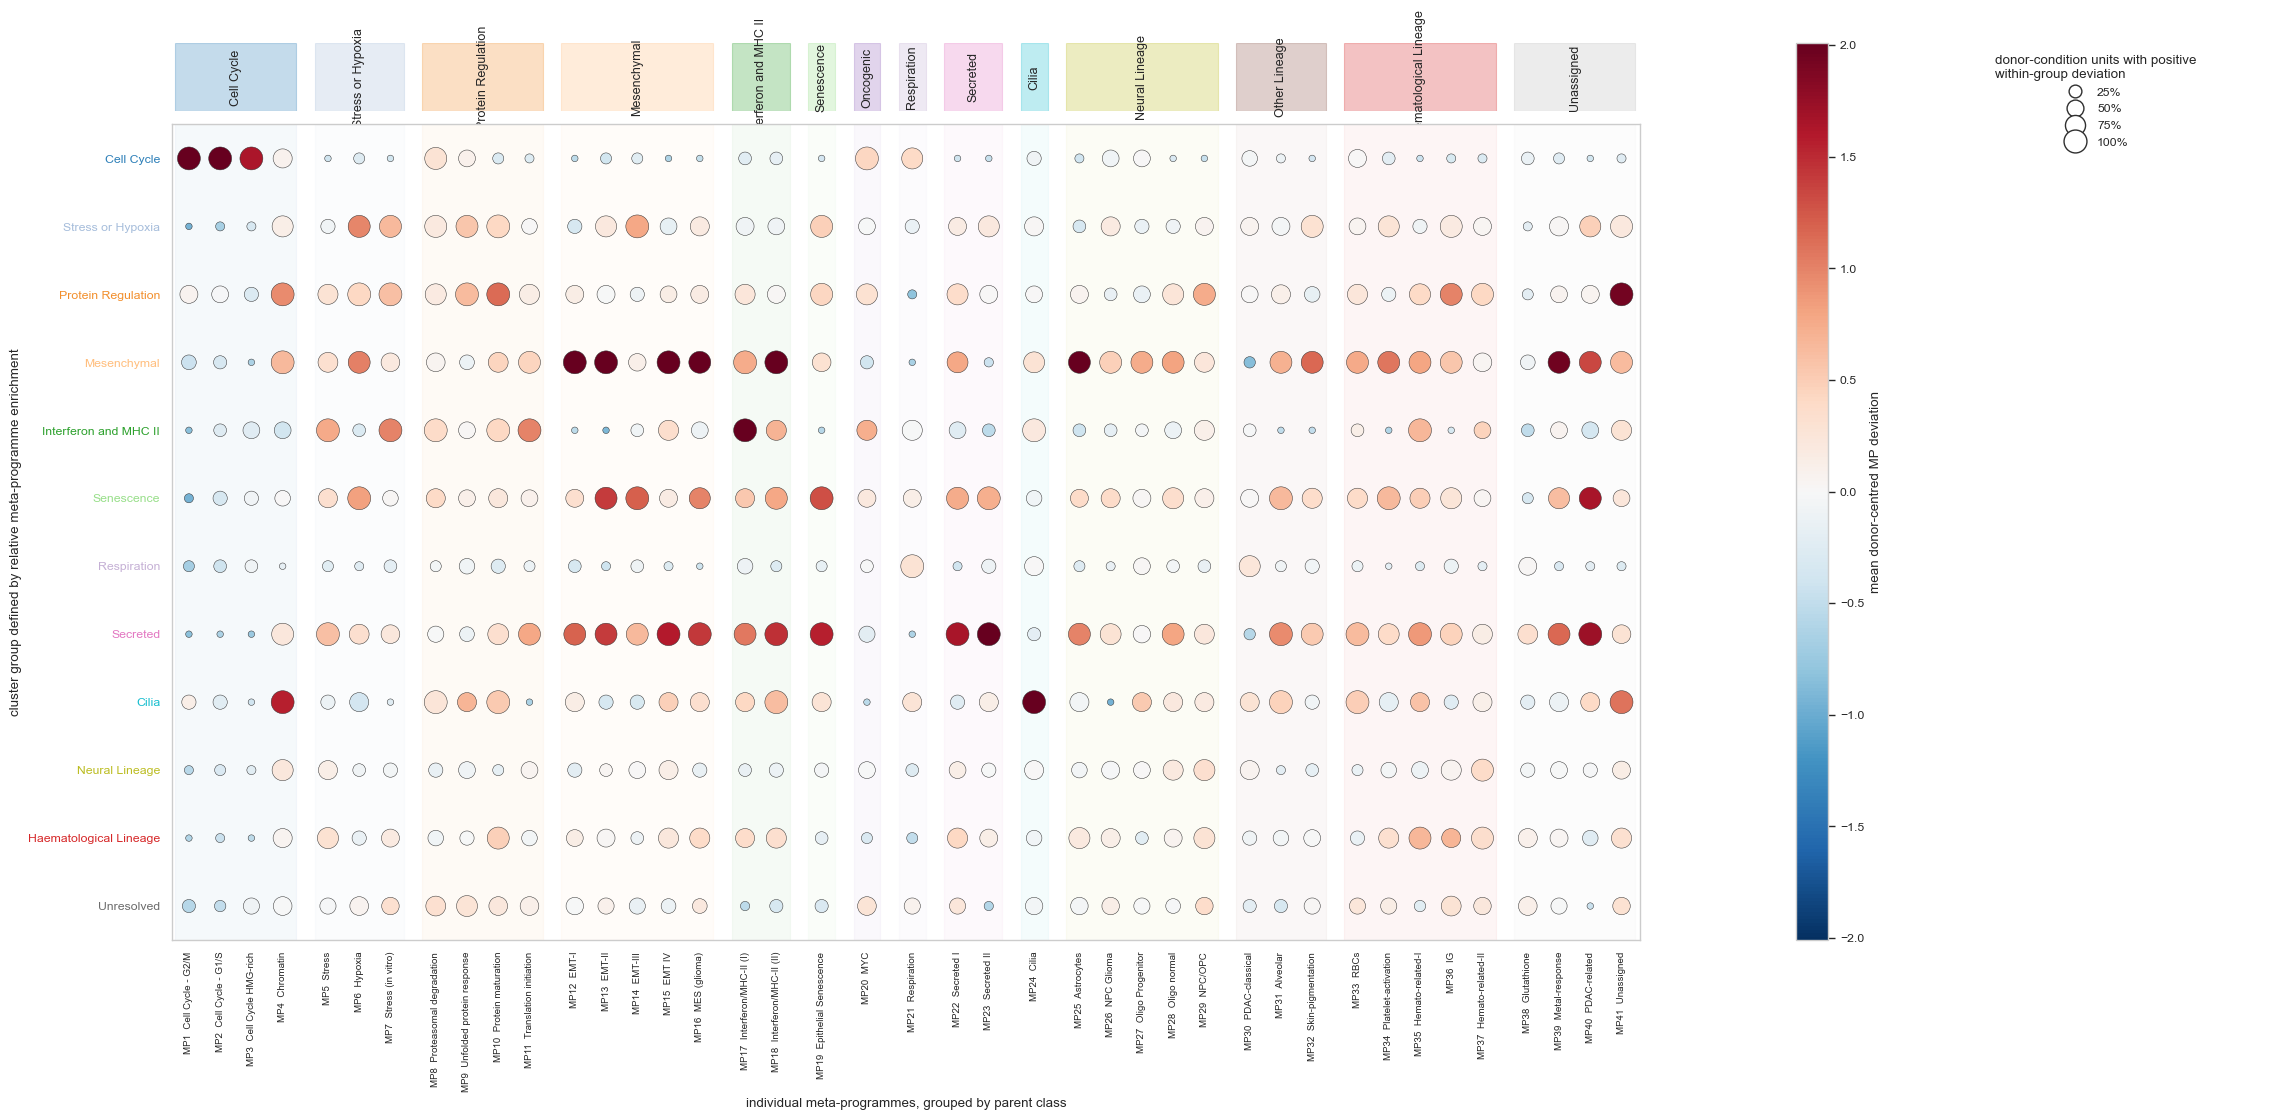

In [126]:
fig = plt.figure(
    figsize=(26, max(11, 0.85 * len(group_order) + 5))
)
grid = fig.add_gridspec(
    2, 3,
    height_ratios=[1.0, max(4, len(group_order))],
    width_ratios=[9, 0.20, 1.8],
    hspace=0.03,
    wspace=0.26,
)
band_ax = fig.add_subplot(grid[0, 0])
ax = fig.add_subplot(grid[1, 0], sharex=band_ax)

colourbar_ax = fig.add_subplot(grid[:, 1])
legend_ax = fig.add_subplot(grid[:, 2])

points = ax.scatter(
    plot_summary["x"],
    plot_summary["y"],
    s=22 + 250 * plot_summary["fraction_units_positive"],
    c=plot_summary["mean_unit_centred_deviation"],
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    edgecolor="#303030",
    linewidth=0.35,
    zorder=3,
)

parent_palette = {**programme_palette, "Unassigned": "#BDBDBD"}

for parent_class, start, end in parent_spans:
    colour = parent_palette.get(parent_class, "#BDBDBD")
    band_ax.axvspan(start - 0.43, end + 0.43, color=colour, alpha=0.28)
    band_ax.text(
        (start + end) / 2,
        0.5,
        parent_class,
        rotation=90,
        ha="center",
        va="center",
        fontsize=9,
    )
    ax.axvspan(start - 0.43, end + 0.43, color=colour, alpha=0.045, zorder=0)

band_ax.set_ylim(0, 1)
band_ax.axis("off")

ax.set_xticks(
    [mp_x[mp] for mp in mp_order],
    [mp_axis_labels[mp] for mp in mp_order],
    rotation=90,
    fontsize=7,
)
ax.set_yticks(range(len(group_order)), group_order)
ax.set_xlim(-0.55, x_cursor - 0.85)
ax.set_ylim(len(group_order) - 0.5, -0.5)

ax.set_xlabel("individual meta-programmes, grouped by parent class")
ax.set_ylabel("cluster group defined by relative meta-programme enrichment")
ax.grid(False)

display_palette = {**programme_palette, "Unresolved": "#6B6B6B"}

for tick in ax.get_yticklabels():
    tick.set_color(display_palette.get(tick.get_text(), "#303030"))

colourbar = fig.colorbar(points, cax=colourbar_ax)
colourbar.set_label("mean donor-centred MP deviation")

legend_ax.axis("off")

legend_ax.legend(
    handles=[
        Line2D(
            [], [], linestyle="none", marker="o",
            markersize=np.sqrt(22 + 250 * fraction),
            markerfacecolor="white", markeredgecolor="#303030",
            label=f"{fraction:.0%}",
        )
        for fraction in [0.25, 0.50, 0.75, 1.00]
    ],
    title="donor-condition units with positive\nwithin-group deviation",
    loc="upper left",
    frameon=False,
)

fig.subplots_adjust(left=0.17, right=0.98, bottom=0.38, top=0.97)

for suffix in ["svg", "pdf", "png"]:
    fig.savefig(
        fig_dir / f"meta_programme_cluster_enrichment_bubble.{suffix}",
        dpi=600 if suffix == "png" else None,
        bbox_inches="tight",
    )

plt.show()


In [127]:
group_mp_summary.to_csv(
    df_dir / "meta_programme_cluster_enrichment_bubble.csv", index=False
)
plot_summary.to_csv(
    df_dir / "meta_programme_cluster_enrichment_bubble_plotted.csv", index=False
)
group_mp_long.to_csv(
    df_dir / "meta_programme_cluster_enrichment_by_unit.csv", index=False
)


In [128]:
donor_heatmap = (
    unit_composition
    .set_index([condition_key, "analysis_unit"])[composition_categories]
    .sort_index(level=[0, 1])
)


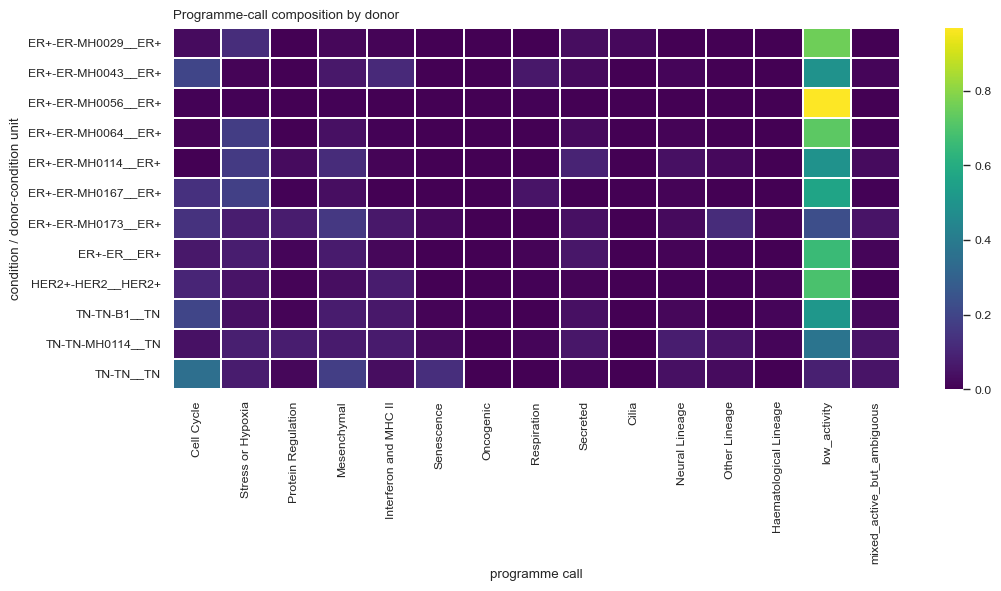

In [129]:
fig, ax = plt.subplots(figsize=(11, max(6, 0.28 * len(donor_heatmap))))

sns.heatmap(
    donor_heatmap,
    cmap="viridis",
    vmin=0,
    vmax=max(0.25, float(donor_heatmap.to_numpy().max())),
    linewidths=0.15,
    linecolor="white",
    ax=ax,
)
ax.set_xlabel("programme call")
ax.set_ylabel("condition / donor-condition unit")
ax.set_title("Programme-call composition by donor", loc="left")

fig.tight_layout()
fig.savefig(fig_dir / "meta_programme_hallmark_by_donor_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


## Programme-wise condition tests

Each programme is tested across conditions with a donor-level Kruskal statistic
and 9,999 label permutations. Holm correction controls multiplicity across the
13 parent classes. The asymptotic p-value is retained only as a diagnostic.


In [130]:
def kruskal_permutation_test(values, labels, levels, permutations, seed):
    values = np.asarray(values, dtype=float)
    labels = np.asarray(labels, dtype=str)

    if np.allclose(values, values[0]):
        return 0.0, 1.0, 1.0

    groups = [values[labels == level] for level in levels]
    observed, asymptotic_p = kruskal(*groups)

    ranks = rankdata(values)
    _, tie_counts = np.unique(values, return_counts=True)
    n = len(values)
    tie_correction = 1 - np.sum(tie_counts**3 - tie_counts) / (n**3 - n)
    group_sizes = {level: np.sum(labels == level) for level in levels}

    rng = np.random.default_rng(seed)
    extreme = 0
    for _ in range(permutations):
        shuffled = rng.permutation(labels)
        rank_term = sum(
            ranks[shuffled == level].sum() ** 2 / group_sizes[level]
            for level in levels
        )
        permuted = 12 * rank_term / (n * (n + 1)) - 3 * (n + 1)
        permuted /= tie_correction
        extreme += permuted >= observed - 1e-12

    permutation_p = (extreme + 1) / (permutations + 1)
    return float(observed), float(asymptotic_p), float(permutation_p)


In [131]:
def programme_condition_tests(composition, label):
    rows = []
    labels = composition[condition_key].astype(str).to_numpy()

    for programme in candidate_hallmarks:
        statistic, asymptotic_p, permutation_p = kruskal_permutation_test(
            composition[programme],
            labels,
            condition_order,
            n_permutations,
            stable_seed(f"kruskal::{label}::{programme}"),
        )
        rows.append({
            "programme": programme,
            "kruskal_h": statistic,
            "p_asymptotic": asymptotic_p,
            "p_permutation": permutation_p,
        })

    result = pd.DataFrame(rows)
    result["p_holm"] = multipletests(
        result["p_permutation"], method="holm"
    )[1]
    return result


In [132]:
programme_tests = programme_condition_tests(unit_composition, "primary")
programme_tests_min_genes = programme_condition_tests(
    unit_composition_min_genes, "min_500_genes"
)
programme_tests_cnv_high = programme_condition_tests(
    unit_composition_cnv_high, "cnv_high"
)

programme_tests.to_csv(
    df_dir / "meta_programme_condition_tests.csv", index=False
)


In [133]:
programme_tests_cnv_high_g1 = programme_condition_tests(
    unit_composition_cnv_high_g1, "cnv_high_g1"
)


In [134]:
programme_tests_min_genes.to_csv(
    df_dir / "meta_programme_condition_tests_min_500_genes.csv", index=False
)
programme_tests_cnv_high.to_csv(
    df_dir / "meta_programme_condition_tests_cnv_high.csv", index=False
)
display(programme_tests.sort_values("p_permutation").round(4))
display(programme_tests_min_genes.sort_values("p_permutation").round(4))
display(programme_tests_cnv_high.sort_values("p_permutation").round(4))


,programme,kruskal_h,p_asymptotic,p_permutation,p_holm
6,Oncogenic,5.4580,0.0653,0.0314,0.4082
5,Senescence,5.3429,0.0692,0.0364,0.4368
12,Haematological Lineage,4.9327,0.0849,0.0492,0.5412
10,Neural Lineage,4.2404,0.1200,0.0871,0.8710
4,Interferon and MHC II,3.2949,0.1925,0.1664,1.0000
9,Cilia,3.1800,0.2039,0.2015,1.0000
3,Mesenchymal,3.0353,0.2192,0.2108,1.0000
0,Cell Cycle,2.6506,0.2657,0.2974,1.0000
2,Protein Regulation,2.0769,0.3540,0.4209,1.0000
8,Secreted,1.4712,0.4792,0.5710,1.0000


,programme,kruskal_h,p_asymptotic,p_permutation,p_holm
6,Oncogenic,7.2008,0.0273,0.0177,0.2301
5,Senescence,5.3429,0.0692,0.0399,0.4788
12,Haematological Lineage,4.9327,0.0849,0.0464,0.5104
10,Neural Lineage,4.2404,0.1200,0.0874,0.8740
3,Mesenchymal,3.6026,0.1651,0.1343,1.0000
9,Cilia,3.1800,0.2039,0.1899,1.0000
4,Interferon and MHC II,2.9872,0.2246,0.2201,1.0000
0,Cell Cycle,2.6506,0.2657,0.3031,1.0000
2,Protein Regulation,2.0769,0.3540,0.4222,1.0000
1,Stress or Hypoxia,1.8718,0.3922,0.4733,1.0000


,programme,kruskal_h,p_asymptotic,p_permutation,p_holm
6,Oncogenic,9.9265,0.0070,0.0042,0.0546
5,Senescence,4.4125,0.1101,0.0461,0.5532
0,Cell Cycle,4.6023,0.1001,0.0519,0.5709
10,Neural Lineage,4.1071,0.1283,0.0870,0.8700
12,Haematological Lineage,3.0671,0.2158,0.2099,1.0000
3,Mesenchymal,2.7273,0.2557,0.2957,1.0000
4,Interferon and MHC II,2.4205,0.2981,0.3876,1.0000
1,Stress or Hypoxia,1.6364,0.4412,0.5486,1.0000
9,Cilia,2.0122,0.3656,0.5500,1.0000
7,Respiration,1.1416,0.5651,0.6722,1.0000


In [135]:
programme_tests_cnv_high_g1.to_csv(
    df_dir / "meta_programme_condition_tests_cnv_high_g1.csv", index=False
)
display(programme_tests_cnv_high_g1.sort_values("p_permutation").round(4))


,programme,kruskal_h,p_asymptotic,p_permutation,p_holm
6,Oncogenic,7.8750,0.0195,0.0279,0.3627
10,Neural Lineage,4.9885,0.0826,0.0425,0.5100
5,Senescence,4.9885,0.0826,0.0427,0.5100
8,Secreted,4.2000,0.1225,0.0972,0.9720
3,Mesenchymal,3.0889,0.2134,0.2082,1.0000
2,Protein Regulation,2.4202,0.2982,0.3677,1.0000
0,Cell Cycle,2.2409,0.3261,0.4057,1.0000
4,Interferon and MHC II,2.0222,0.3638,0.4786,1.0000
9,Cilia,1.9059,0.3856,0.5582,1.0000
1,Stress or Hypoxia,1.6222,0.4444,0.5619,1.0000


## Complete programme profile



Condition differences are tested on Hellinger-transformed donor-level
composition profiles with a Euclidean pseudo-F statistic and 9,999 label
permutations. A centroid-distance permutation test checks whether a global
result could reflect unequal within-condition dispersion. Pairwise tests are
interpreted only when the global test is significant.


In [136]:
def multivariate_f(values, labels):
    values = np.asarray(values, float)
    labels = np.asarray(labels)
    groups = np.unique(labels)

    grand_mean = values.mean(axis=0)
    total = np.square(values - grand_mean).sum()
    between = sum(
        (labels == group).sum()
        * np.square(values[labels == group].mean(axis=0) - grand_mean).sum()
        for group in groups
    )
    within = total - between
    statistic = (between / (len(groups) - 1)) / (within / (len(values) - len(groups)))
    return float(statistic), float(between / total)


In [137]:
def permutation_test(values, labels, permutations, seed):
    observed, r_squared = multivariate_f(values, labels)
    rng = np.random.default_rng(seed)
    null = np.empty(permutations)

    for index in range(permutations):
        null[index], _ = multivariate_f(values, rng.permutation(labels))

    p_value = (1 + np.count_nonzero(null >= observed)) / (permutations + 1)
    return observed, r_squared, p_value


In [138]:
profile_values = np.sqrt(unit_composition[composition_categories].to_numpy(float))
profile_conditions = unit_composition[condition_key].astype(str).to_numpy()

global_f, global_r2, global_p = permutation_test(
    profile_values,
    profile_conditions,
    permutations=n_permutations,
    seed=random_seed,
)


In [139]:
global_test = pd.DataFrame([{
    "n_analysis_units": len(unit_composition),
    "n_profile_categories": len(composition_categories),
    "pseudo_f": global_f,
    "r_squared": global_r2,
    "p_value": global_p,
    "n_permutations": n_permutations,
    "seed": random_seed,
}])
global_test.to_csv(df_dir / "meta_programme_programme_global_permanova.csv", index=False)
display(global_test.round(4))


,n_analysis_units,n_profile_categories,pseudo_f,r_squared,p_value,n_permutations,seed
0,12,15,1.4572,0.2446,0.218,9999,0


In [140]:
sensitivity_values = np.sqrt(
    unit_composition_min_genes[composition_categories].to_numpy(float)
)
sensitivity_conditions = unit_composition_min_genes[condition_key].astype(str).to_numpy()

sensitivity_f, sensitivity_r2, sensitivity_p = permutation_test(
    sensitivity_values,
    sensitivity_conditions,
    permutations=n_permutations,
    seed=stable_seed("permanova::min_500_genes"),
)


In [141]:
global_test_min_genes = pd.DataFrame([{
    "n_analysis_units": len(unit_composition_min_genes),
    "n_profile_categories": len(composition_categories),
    "pseudo_f": sensitivity_f,
    "r_squared": sensitivity_r2,
    "p_value": sensitivity_p,
    "n_permutations": n_permutations,
    "seed_label": "permanova::min_500_genes",
}])
global_test_min_genes.to_csv(
    df_dir / "meta_programme_global_permanova_min_500_genes.csv", index=False
)


In [142]:
display(global_test_min_genes.round(4))

cnv_high_values = np.sqrt(
    unit_composition_cnv_high[composition_categories].to_numpy(float)
)
cnv_high_conditions = unit_composition_cnv_high[condition_key].astype(str).to_numpy()


,n_analysis_units,n_profile_categories,pseudo_f,r_squared,p_value,n_permutations,seed_label
0,12,15,1.692,0.2733,0.1389,9999,permanova::min_500_genes


In [143]:
cnv_high_f, cnv_high_r2, cnv_high_p = permutation_test(
    cnv_high_values,
    cnv_high_conditions,
    permutations=n_permutations,
    seed=stable_seed("permanova::cnv_high"),
)


In [144]:
global_test_cnv_high = pd.DataFrame([{
    "n_analysis_units": len(unit_composition_cnv_high),
    "n_profile_categories": len(composition_categories),
    "pseudo_f": cnv_high_f,
    "r_squared": cnv_high_r2,
    "p_value": cnv_high_p,
    "n_permutations": n_permutations,
    "seed_label": "permanova::cnv_high",
}])
global_test_cnv_high.to_csv(
    df_dir / "meta_programme_global_permanova_cnv_high.csv", index=False
)


In [145]:
display(global_test_cnv_high.round(4))


,n_analysis_units,n_profile_categories,pseudo_f,r_squared,p_value,n_permutations,seed_label
0,11,15,1.8219,0.3129,0.1167,9999,permanova::cnv_high


### Leave-one-donor-out sensitivity

The global profile test is repeated after omitting each donor-condition unit. This checks whether its interpretation depends on one donor.

In [146]:
loo_rows = []
analysis_units = unit_composition["analysis_unit"].astype(str).to_numpy()


In [147]:
for omitted_unit in analysis_units:
    keep = analysis_units != omitted_unit
    statistic, r_squared, p_value = permutation_test(
        profile_values[keep],
        profile_conditions[keep],
        permutations=n_permutations,
        seed=stable_seed(f"permanova_loo::{omitted_unit}"),
    )
    loo_rows.append({
        "omitted_analysis_unit": omitted_unit,
        "omitted_condition": profile_conditions[~keep][0],
        "n_analysis_units": int(keep.sum()),
        "pseudo_f": statistic,
        "r_squared": r_squared,
        "p_value": p_value,
        "n_permutations": n_permutations,
    })


In [148]:
permanova_loo = pd.DataFrame(loo_rows).sort_values("p_value")
permanova_loo.to_csv(
    df_dir / "meta_programme_programme_global_permanova_leave_one_donor_out.csv",
    index=False,
)
display(permanova_loo.round(4))


,omitted_analysis_unit,omitted_condition,n_analysis_units,pseudo_f,r_squared,p_value,n_permutations
8,HER2__HER2+,HER2+,11,2.5453,0.2205,0.0726,9999
6,ER-MH0173__ER+,ER+,11,2.1685,0.3515,0.1096,9999
1,ER-MH0043__ER+,ER+,11,1.6886,0.2968,0.1823,9999
9,TN-B1__TN,TN,11,1.6250,0.2889,0.1834,9999
10,TN-MH0114__TN,TN,11,1.4626,0.2678,0.2212,9999
2,ER-MH0056__ER+,ER+,11,1.3131,0.2471,0.2445,9999
4,ER-MH0114__ER+,ER+,11,1.4014,0.2594,0.2484,9999
5,ER-MH0167__ER+,ER+,11,1.3687,0.2549,0.2579,9999
7,ER__ER+,ER+,11,1.2733,0.2415,0.2934,9999
3,ER-MH0064__ER+,ER+,11,1.2120,0.2325,0.3188,9999


In [149]:
def dispersion_statistic(values, labels):
    values = np.asarray(values, float)
    labels = np.asarray(labels)
    groups = np.unique(labels)
    distances = np.empty(len(values))

    for group in groups:
        mask = labels == group
        centroid = values[mask].mean(axis=0)
        distances[mask] = np.linalg.norm(values[mask] - centroid, axis=1)

    grand_mean = distances.mean()
    between = sum(
        (labels == group).sum()
        * (distances[labels == group].mean() - grand_mean) ** 2
        for group in groups
    )
    within = sum(
        np.square(distances[labels == group] - distances[labels == group].mean()).sum()
        for group in groups
    )
    return float(
        (between / (len(groups) - 1))
        / (within / (len(values) - len(groups)))
    )


In [150]:
observed_dispersion = dispersion_statistic(profile_values, profile_conditions)
rng = np.random.default_rng(random_seed)
null_dispersion = np.array([
    dispersion_statistic(profile_values, rng.permutation(profile_conditions))
    for _ in range(n_permutations)
])
dispersion_p = (
    1 + np.count_nonzero(null_dispersion >= observed_dispersion)
) / (n_permutations + 1)


In [151]:
dispersion_test = pd.DataFrame([{
    "f_statistic": observed_dispersion,
    "p_value": dispersion_p,
    "n_permutations": n_permutations,
    "seed": random_seed,
}])
dispersion_test.to_csv(df_dir / "meta_programme_programme_permdisp.csv", index=False)
display(dispersion_test.round(4))


,f_statistic,p_value,n_permutations,seed
0,3.1608,0.7971,9999,0


In [152]:
pair_rows = []
condition_pairs = [("TN", "HER2+"), ("TN", "ER+"), ("HER2+", "ER+")]


In [153]:
for pair_index, (left, right) in enumerate(condition_pairs, start=1):
    keep = np.isin(profile_conditions, [left, right])
    statistic, r_squared, p_value = permutation_test(
        profile_values[keep],
        profile_conditions[keep],
        permutations=n_permutations,
        seed=random_seed + pair_index,
    )
    pair_rows.append({
        "condition_a": left,
        "condition_b": right,
        "n_analysis_units": int(keep.sum()),
        "pseudo_f": statistic,
        "r_squared": r_squared,
        "p_value": p_value,
        "n_permutations": n_permutations,
        "seed": random_seed + pair_index,
    })


In [154]:
pairwise_tests = pd.DataFrame(pair_rows)
pairwise_tests["p_holm"] = multipletests(
    pairwise_tests["p_value"], method="holm"
)[1]
pairwise_tests["interpret_only_if_global_significant"] = True


In [155]:
pairwise_tests.to_csv(df_dir / "meta_programme_programme_pairwise_permanova.csv", index=False)
display(pairwise_tests.round(4))


,condition_a,condition_b,n_analysis_units,pseudo_f,r_squared,p_value,n_permutations,seed,p_holm,interpret_only_if_global_significant
0,TN,HER2+,4,0.9750,0.3277,0.4973,9999,1,0.9946,True
1,TN,ER+,11,2.5453,0.2205,0.0714,9999,2,0.2142,True
2,HER2+,ER+,9,0.3135,0.0429,0.8909,9999,3,0.9946,True


## UMAP and saved annotations


In [156]:
epi.obs["MP_dominant_class"] = "normal_tissue"
epi.obs.loc[tumour_derived_mask, "MP_dominant_class"] = "not_scored"
epi.obs.loc[scored_cells, "MP_dominant_class"] = programme_call.to_numpy()

epi.obs["MP_programme_call"] = epi.obs["MP_dominant_class"].astype(str)
epi.obs["MP_relative_margin"] = np.nan
epi.obs.loc[scored_cells, "MP_relative_margin"] = display_margin
epi.obs["MP_n_active_mps"] = np.nan


In [157]:
epi.obs.loc[scored_cells, "MP_n_active_mps"] = mp_activity.sum(axis=1).to_numpy()


In [158]:
for hallmark in candidate_hallmarks:
    column = f"MP_{hallmark}"
    epi.obs[column] = np.nan
    epi.obs.loc[scored_cells, column] = class_scores[hallmark].to_numpy()


In [159]:
epi.obs["MP_Mesenchymal_score"] = epi.obs["MP_Mesenchymal"]


In [160]:
for mp_name in mp_relative.columns:
    mp_id = re.match(r"^(MP\d+)", mp_name).group(1)
    epi.obs[f"MP_{mp_id}"] = np.nan
    epi.obs.loc[scored_cells, f"MP_{mp_id}"] = mp_relative[mp_name].to_numpy()
    epi.obs[f"MP_{mp_id}_active"] = np.nan
    epi.obs.loc[scored_cells, f"MP_{mp_id}_active"] = (
        mp_activity[mp_name].astype(float).to_numpy()
    )

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_5592/1674869072.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs[f"MP_{mp_id}"] = np.nan
/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_5592/1674869072.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs[f"MP_{mp_id}_active"] = np.nan
/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_5592/1674869072.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has 

In [161]:
epi.obs["three_ca_style_mp_call"] = "not_scored"
epi.obs.loc[scored_cells, "three_ca_style_mp_call"] = (
    three_ca_mp_call.astype(str).to_numpy()
)
epi.obs["three_ca_style_parent_call"] = "not_scored"
epi.obs.loc[scored_cells, "three_ca_style_parent_call"] = (
    three_ca_parent_call.astype(str).to_numpy()
)
epi.obs["three_ca_style_max_score"] = np.nan
epi.obs.loc[scored_cells, "three_ca_style_max_score"] = (
    three_ca_max_score.to_numpy()
)

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_5592/831466318.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs["three_ca_style_mp_call"] = "not_scored"
/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_5592/831466318.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs["three_ca_style_parent_call"] = "not_scored"
/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_5592/831466318.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.in

In [162]:
hallmark_order = list(candidate_hallmarks)
call_order = candidate_hallmarks + ["low_activity", "mixed_active_but_ambiguous"]
hallmark_colors = [programme_palette[hallmark] for hallmark in hallmark_order]

epi.obs["MP_dominant_class"] = epi.obs["MP_dominant_class"].astype("category")
epi.obs["MP_programme_call"] = epi.obs["MP_programme_call"].astype("category")
epi.obs["three_ca_style_mp_call"] = epi.obs["three_ca_style_mp_call"].astype("category")
epi.obs["three_ca_style_parent_call"] = epi.obs["three_ca_style_parent_call"].astype("category")
epi.uns["meta_programme_hallmark_order"] = hallmark_order
epi.uns["meta_programme_hallmark_colors"] = hallmark_colors
epi.uns["meta_programme_mp_names"] = {
    re.match(r"^(MP\d+)", name).group(1): name for name in meta_programme_states
}

In [163]:
plot_values = epi.obs["MP_programme_call"].astype(str)
umap = epi.obsm["X_umap"]
point_size = 120_000 / epi.n_obs

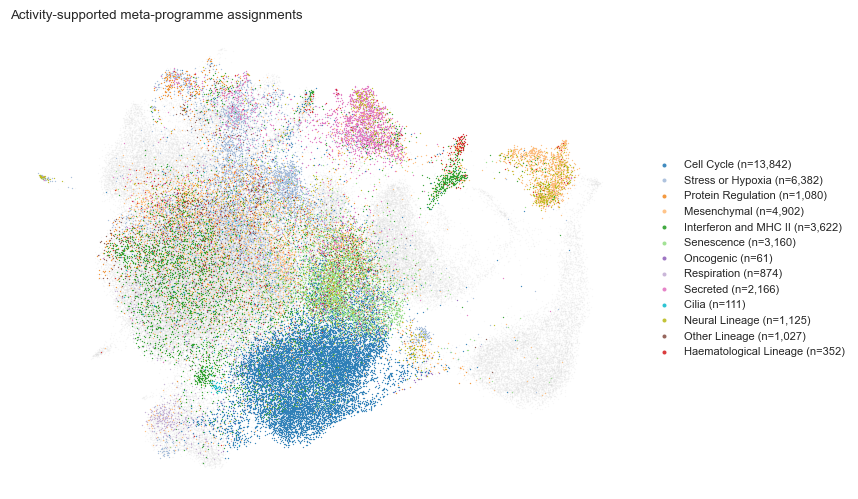

In [164]:
# Draw all epithelial cells first as anatomical context.
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    umap[:, 0],
    umap[:, 1],
    s=point_size,
    color="#D9D9D9",
    alpha=0.18,
    linewidths=0,
    rasterized=True,
)

# Overlay activity-supported assignments after the background.
for programme in candidate_hallmarks:
    mask = (plot_values == programme).to_numpy()
    ax.scatter(
        umap[mask, 0],
        umap[mask, 1],
        s=point_size,
        color=programme_palette[programme],
        alpha=0.9,
        linewidths=0,
        rasterized=True,
        label=f"{programme} (n={mask.sum():,})",
    )

ax.set_title("Activity-supported meta-programme assignments", loc="left")
ax.set_axis_off()
ax.legend(
    bbox_to_anchor=(1.02, 0.5), loc="center left", frameon=False,  markerscale=3, fontsize=8)
fig.savefig(fig_dir / "meta_programme_assignments_umap.png", dpi=300, bbox_inches="tight")
plt.show()

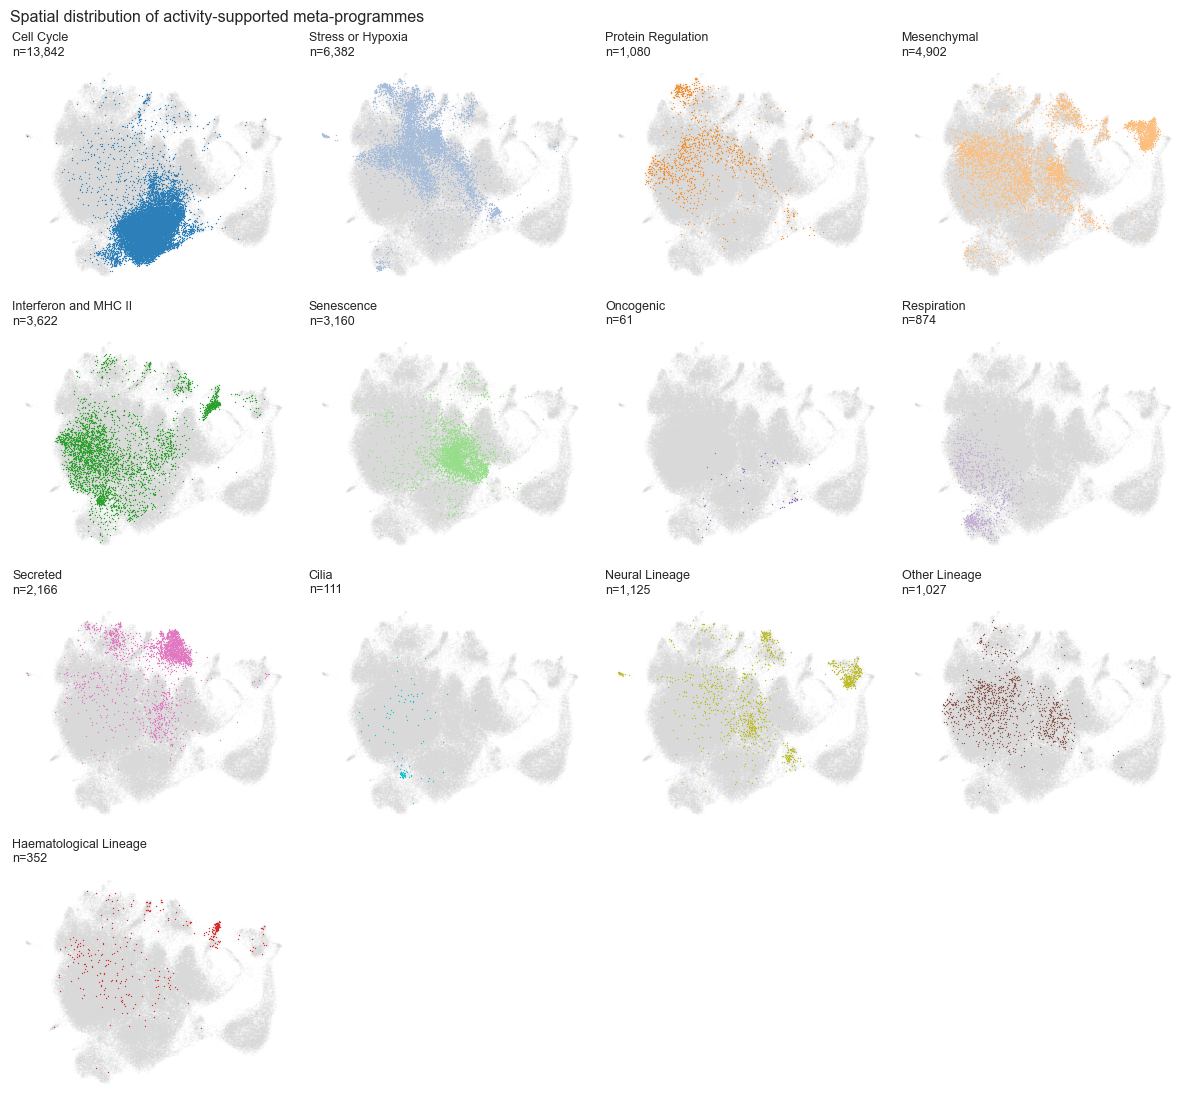

In [165]:
# Small multiples separate spatially overlapping programme classes.
n_columns = 4
n_rows = int(np.ceil(len(candidate_hallmarks) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(12, 2.8 * n_rows))

for ax, programme in zip(axes.flat, candidate_hallmarks):
    mask = (plot_values == programme).to_numpy()
    ax.scatter(
        umap[:, 0],
        umap[:, 1],
        s=point_size,
        color="#D9D9D9",
        alpha=0.12,
        linewidths=0,
        rasterized=True,
    )
    ax.scatter(
        umap[mask, 0],
        umap[mask, 1],
        s=point_size,
        color=programme_palette[programme],
        alpha=0.95,
        linewidths=0,
        rasterized=True,
    )
    ax.set_title(f"{programme}\nn={mask.sum():,}", fontsize=9, loc="left")
    ax.set_axis_off()

for ax in axes.flat[len(candidate_hallmarks):]:
    ax.set_visible(False)

fig.suptitle("Spatial distribution of activity-supported meta-programmes", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(fig_dir / "meta_programme_assignments_umap_facets.png", dpi=300, bbox_inches="tight")
plt.show()

## Save


In [166]:
assert epi.obs.loc[scored_cells, "MP_programme_call"].notna().all()
assert epi.obs.loc[scored_cells, "MP_Mesenchymal_score"].notna().all()
assert epi.obs.loc[scored_cells, "three_ca_style_parent_call"].notna().all()
assert set(programme_call.unique()).issubset(set(call_order))


In [167]:
epi.uns["meta_programme_analysis"] = {
    "signature_source": signature_source,
    "signature_source_url": signature_source_url,
    "signature_sha256": signature_sha256,
    "primary_method": "adapted matched-null projection; not the original 3CA assignment algorithm",
    "score": "mean log-normalised signature expression minus fixed matched controls",
    "activity": (
        f"empirical expression-matched null p-values; Holm-adjusted within cell "
        f"at familywise alpha {activity_familywise_alpha:.2f}; at least "
        f"{min_detected_signature_fraction:.2f} of genes detected"
    ),
    "programme_call": (
        f"best active class; multiple active classes require margin >= {top2_margin:.2f}"
    ),
    "condition_unit": "donor by condition; technical samples averaged within unit",
    "condition_unit_independence": "one retained condition per donor after eligibility filtering",
    "cluster_summary": "donor-centred relative enrichment; not a cell identity",
    "min_cells_per_sample": int(min_cells_per_sample),
    "min_signature_coverage": float(min_signature_coverage),
    "n_expression_bins": int(n_expression_bins),
    "n_controls_per_gene": int(n_controls_per_gene),
    "n_null_signatures": int(n_null_signatures),
    "three_ca_style_sensitivity": {
        "implementation": "Python reimplementation; not scalop output",
        "method_url": three_ca_method_url,
        "scoring_url": three_ca_scoring_url,
        "transform": "log2(CPM / 10 + 1)",
        "expression_bins": int(three_ca_expression_bins),
        "controls_per_gene": int(three_ca_controls_per_gene),
        "min_genes": int(three_ca_min_genes),
        "min_score": float(three_ca_min_score),
        "min_within_sample_frequency": float(three_ca_min_frequency),
    },
    "seed": int(random_seed),
}


Class-ranking sensitivity. An alternative ranks the all-member class score with its matching scale, retaining the same activity gate and ambiguity margin. This check does not replace the primary calls. Global profile tests and individual programme tests are reported separately; the latter use 99,999 permutations to examine Monte Carlo sensitivity near the significance threshold.

In [168]:
import sys
repository = find_publication()
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))
check_dir = repository / "results" / "publication_checks"
check_dir.mkdir(parents=True, exist_ok=True)

from scripts.publication_targeted_checks import class_ranking_sensitivity

ranking_global, ranking_counts = class_ranking_sensitivity(epi, df_dir, check_dir)
display(ranking_global)
display(ranking_counts)


,method,n_units,r_squared,p_permutation,cell_assignment_agreement,agreement_among_activity_supported,agreement_among_both_biologically_assigned
0,primary,12,NaN,NaN,0.939828,0.845042,0.904738
1,all_member_ranking,12,NaN,NaN,0.939828,0.845042,0.904738


,primary,all_member_ranking
low_activity,63231,63231
Cell Cycle,13842,12837
Stress or Hypoxia,6382,6021
Mesenchymal,4902,4667
Interferon and MHC II,3622,4207
Senescence,3160,5556
Secreted,2166,2042
mixed_active_but_ambiguous,1436,1623
Neural Lineage,1125,448
Protein Regulation,1080,766


In [169]:
out_path = save_dir / "epithelial_meta_programmes.h5ad"
tmp_path = out_path.with_suffix(".h5ad.tmp")


In [170]:
for layer in epi.layers:
    if not sp.issparse(epi.layers[layer]):
        epi.layers[layer] = sp.csr_matrix(epi.layers[layer])


In [171]:
assert not epi.uns.get("figure_only", False), "Plotting-only object: do not run analysis save cells."

epi.write_h5ad(tmp_path, compression="gzip")
os.replace(tmp_path, out_path)

check = sc.read_h5ad(out_path, backed="r")
assert check.shape == epi.shape
del check

display(pd.DataFrame({"saved": [out_path.name], "cells": [epi.n_obs], "genes": [epi.n_vars]}))

KeyboardInterrupt: 

In [ ]:
import session_info
session_info.show()

Figures

In [176]:
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}

In [174]:
# draw N first so that the tumour conditions are not hidden underneath it
draw_order = ["N", "TN", "HER2+", "ER+"]
rank = {condition: i for i, condition in enumerate(draw_order)}

plot_idx = epi.obs["condition"].astype(str).map(rank).sort_values().index

In [ ]:
sc.pl.umap(epi[plot_idx],
    color="condition",
    palette=condition_palette, frameon=True,
    show=False)

ax = plt.gca()
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)


ax.tick_params(axis="both", labelsize=12)

legend = ax.get_legend()


if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])

plt.savefig(fig_dir / "epithelial_umap_condition.svg", dpi=300, bbox_inches="tight")
plt.show()

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


KeyboardInterrupt: 

Error in callback <function _draw_all_if_interactive at 0x123ccb600> (for post_execute):


In [ ]:

gc.collect

In [ ]:
#changes for git